# CDP Unlocking Climatic Solutions

In [129]:
# import standard libs
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [130]:
# import city response dataset
df_city_resp_18 = pd.read_csv(r'datasets\Cities\Cities Responses\2018_Full_Cities_Dataset.csv')

# import city disclosing dataset
df_city_disc_18 = pd.read_csv(r'datasets\Cities\Cities Disclosing\2018_Cities_Disclosing_to_CDP.csv')

In [131]:
print("Len of dataframe: ",len(df_city_disc_18))
print("Number of Account_number: ".upper(),len(df_city_disc_18['Account Number'].unique()))
print("Number of Organization: ".upper(),len(df_city_disc_18['Organization'].unique()))

Len of dataframe:  641
NUMBER OF ACCOUNT_NUMBER:  641
NUMBER OF ORGANIZATION:  641


In [132]:
df_city_disc_18.isnull().sum()

Year Reported to CDP     0
Account Number           0
Organization             0
City                     0
Country                  0
CDP Region               0
Reporting Authority      0
Access                   0
First Time Discloser     0
Population              55
Population Year          0
City Location            0
Last update              0
dtype: int64

Only population column of dataset has NULL values => replacing them by mean of population data

In [5]:
df_city_disc_18['Population'].fillna(df_city_disc_18['Population'].mean(), inplace = True)

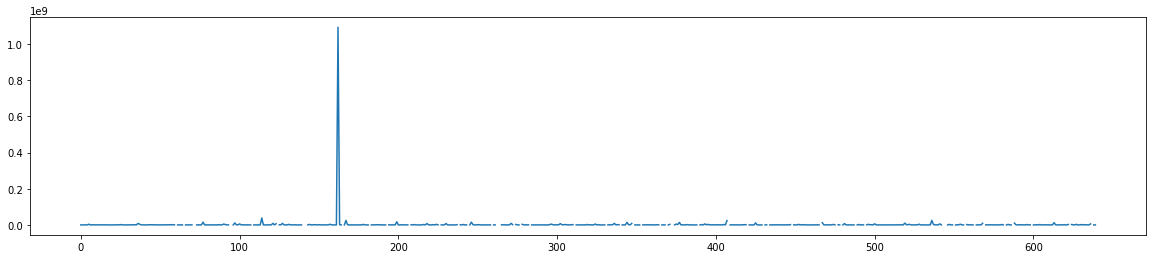

In [133]:
plt.rcParams['figure.figsize'] = (20, 4)
plt.plot(df_city_disc_18['Population'])
plt.show()

The histogram for population has a sharp peak, maybe caused due to error in entry, hence replacing that value by mean of data

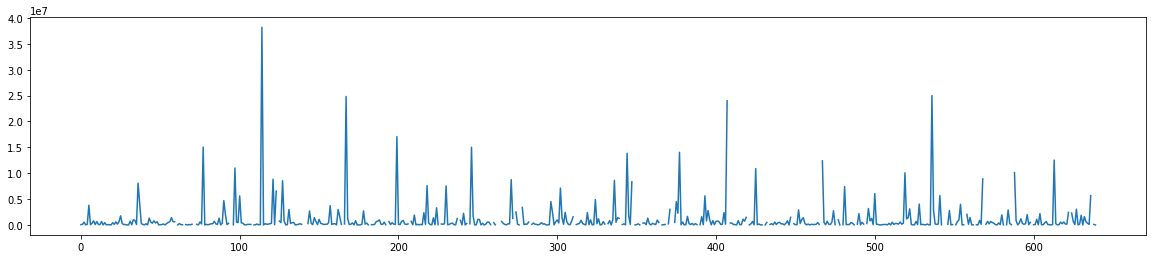

In [134]:
df_city_disc_18['Population'][162] = df_city_disc_18['Population'].mean()
plt.plot(df_city_disc_18['Population'])
plt.show()

## City Responses Data

In [10]:
df_city_resp_18.sample(3)

,Questionnaire,Year Reported to CDP,Account Number,Organization,Country,CDP Region,Parent Section,Section,Question Number,Question Name,Column Number,Column Name,Row Number,Row Name,Response Answer,Comments,File Name,Last update
112788,CDP Cities 2018,2018,58513,City of Medford,United States of America,North America,City Wide Emissions,GHG Emissions Data,7.6d,Where it will facilitate a greater understandi...,1,Source,3,NaN,Residents - Motor gasoline (petrol),NaN,NaN,24/06/2020 05:28:18 AM
48262,CDP Cities 2018,2018,54108,City of Durham,United States of America,North America,Strategy,Energy,9.0,Please indicate the energy mix of electricity ...,4,Nuclear,1,Energy consumption percentage,32,This is statewide data from the EIA for 2017.,NaN,24/06/2020 05:28:18 AM
63483,CDP Cities 2018,2018,50371,Municipalidad de Córdoba,Argentina,Latin America,Governance and Data Management,Governance,1.4a,Please detail which goals and targets are inco...,1,Goal type,3,NaN,Adaptation targets,NaN,NaN,24/06/2020 05:28:18 AM


In [11]:
df_city_resp_18.isnull().sum()

Questionnaire                0
Year Reported to CDP         0
Account Number               0
Organization                 0
Country                      0
CDP Region                   0
Parent Section            3918
Section                      0
Question Number              0
Question Name                0
Column Number                0
Column Name              16567
Row Number                   0
Row Name                118723
Response Answer          59411
Comments                177929
File Name               186007
Last update                  0
dtype: int64

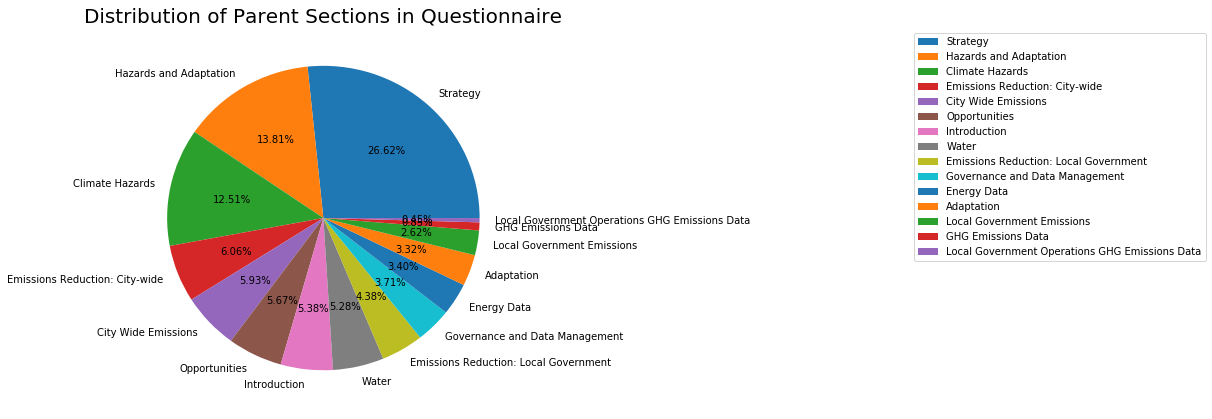

In [136]:
size = df_city_resp_18['Parent Section'].value_counts().values
plt.rcParams['figure.figsize'] = (7, 7)
labels2 = df_city_resp_18['Parent Section'].value_counts().keys()
my_circle = plt.Circle((0, 0), 0.7, color = 'white')
plt.pie(size, labels = labels2, autopct = '%.2f%%')
plt.title('Distribution of Parent Sections in Questionnaire', fontsize = 20)
plt.legend(bbox_to_anchor=(2, 1), loc='upper left',)
plt.show()

In [13]:
## RELATION IN 2 TABLES: 
set_disc = set(df_city_disc_18['Account Number'])
print("Length of disclosing org: ", len(set_disc))
set_resp = set(df_city_resp_18['Account Number'])
print("Length of Responses org: ", len(set_resp))
set_uni = set_disc.union(set_resp)
print("Length of Union of 2 tables: ",len(set_uni))
print("Lenght of diff of disc and union: ", len(set_disc.difference(set_uni)))
print("==> Disclosing set has information of all organisations that are in responses file")

Length of disclosing org:  641
Length of Responses org:  488
Length of Union of 2 tables:  641
Lenght of diff of disc and union:  0
==> Disclosing set has information of all organisations that are in responses file


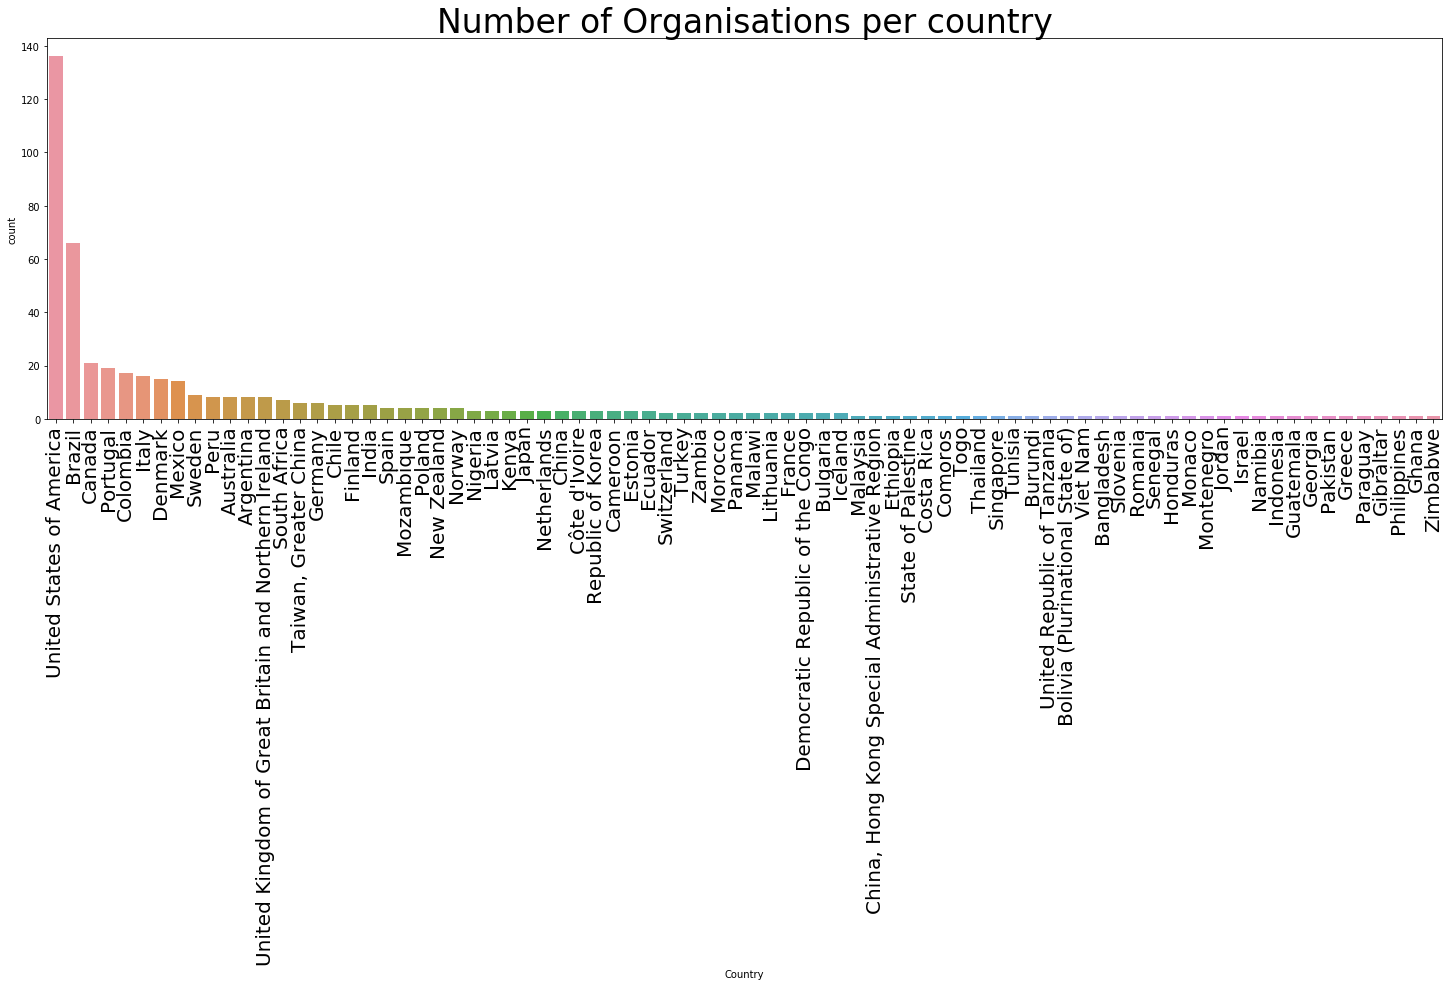

In [14]:
plt.figure(figsize=(25,7))
Y_org_count = list()
grp_org_count = df_city_resp_18.groupby('Country')
for name, group in grp_org_count:
    Y_org_count.append(len(group['Organization'].unique()))
tempdf = pd.DataFrame(list(zip(sorted(df_city_resp_18['Country'].unique()), Y_org_count)), columns = ['Country', 'count']) 
tempdf = tempdf.sort_values(by = ['count'], ascending=False)
sns.barplot(x = tempdf['Country'], y = tempdf['count'])
plt.xticks(rotation=90, fontsize = 20);
plt.title('Number of Organisations per country', fontsize = 33);

Below chart depicts the distribution of 8 CDP Regions and percentage of data present for countries present within each region

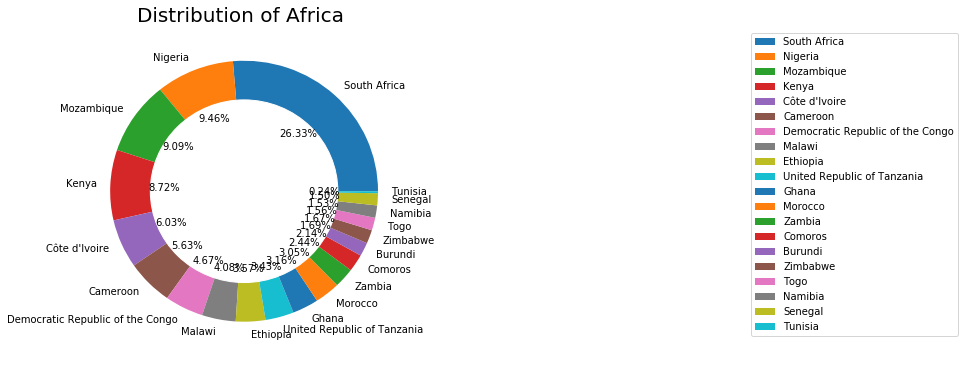

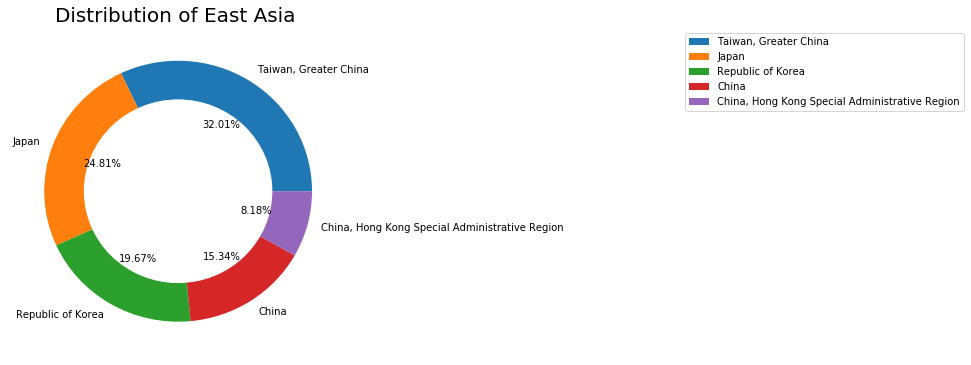

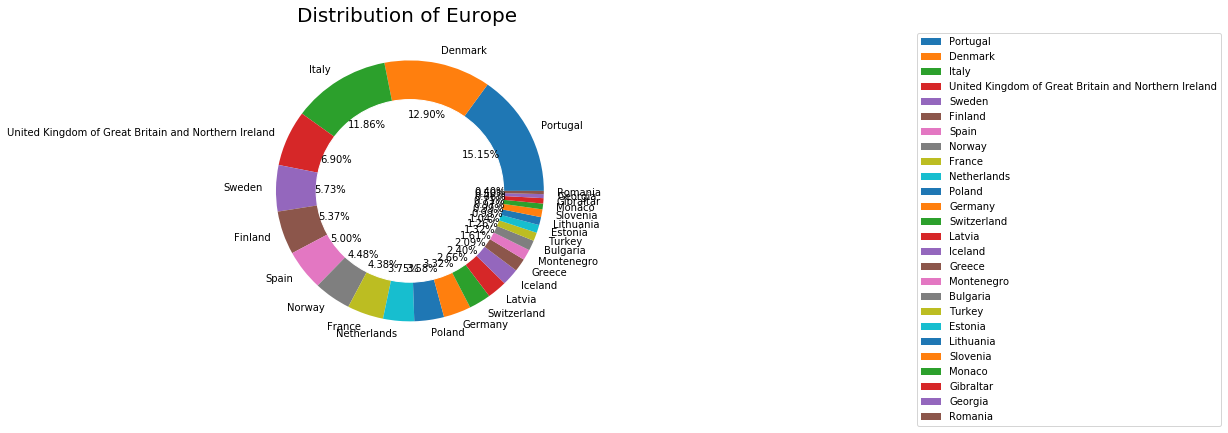

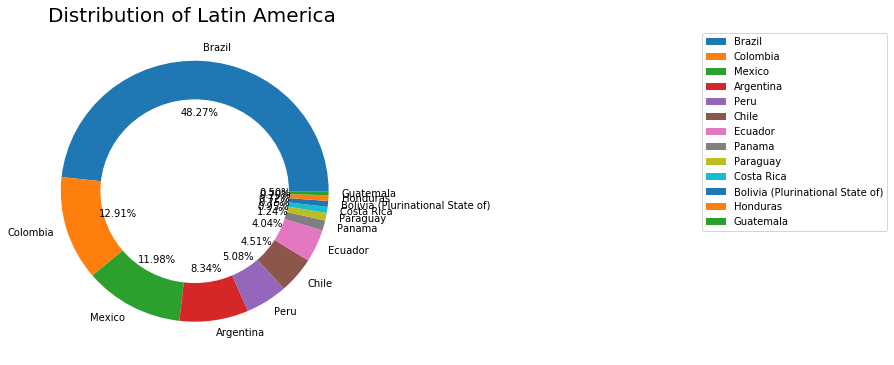

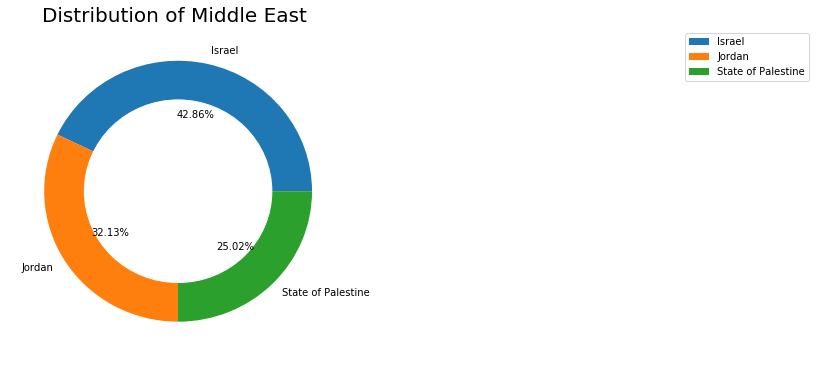

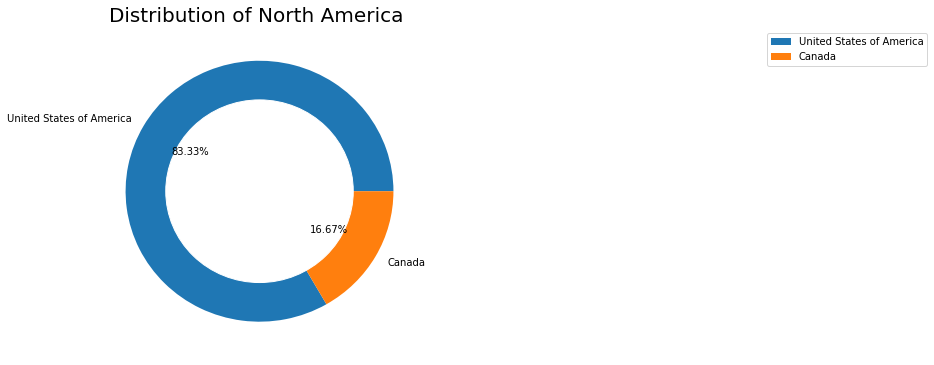

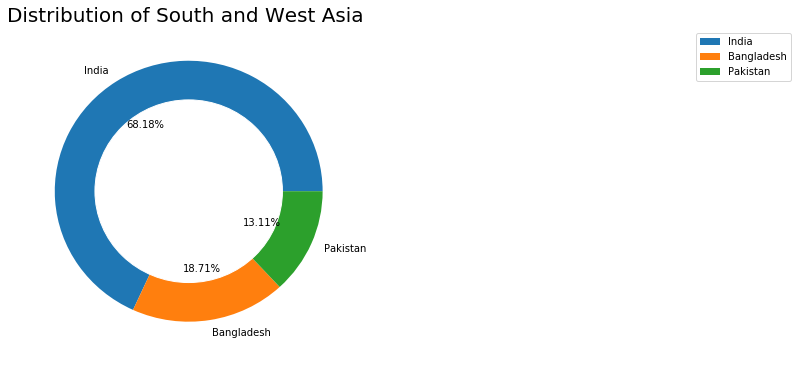

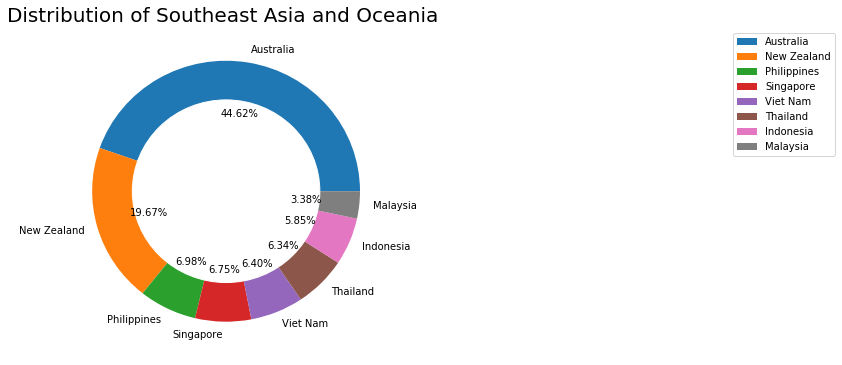

In [15]:
plt.rcParams['figure.figsize'] = (6, 6)
grp_parent = df_city_resp_18.groupby('CDP Region')

for sect, group in grp_parent:
    size = group['Country'].value_counts().values    
    labels2 = group['Country'].value_counts().keys()
    my_circle = plt.Circle((0, 0), 0.7, color = 'white')
    plt.pie(size, labels = labels2, autopct = '%.2f%%')
    plt.title('Distribution of {} '.format(sect), fontsize = 20)
    p = plt.gcf()
    p.gca().add_artist(my_circle)
    plt.legend(bbox_to_anchor=(2, 1), loc='upper left')
    plt.show()

Filling the NaN values in response column of city response dataset with "No Response"

In [16]:
df_city_resp_18['Response Answer'].fillna("No Response", inplace = True)

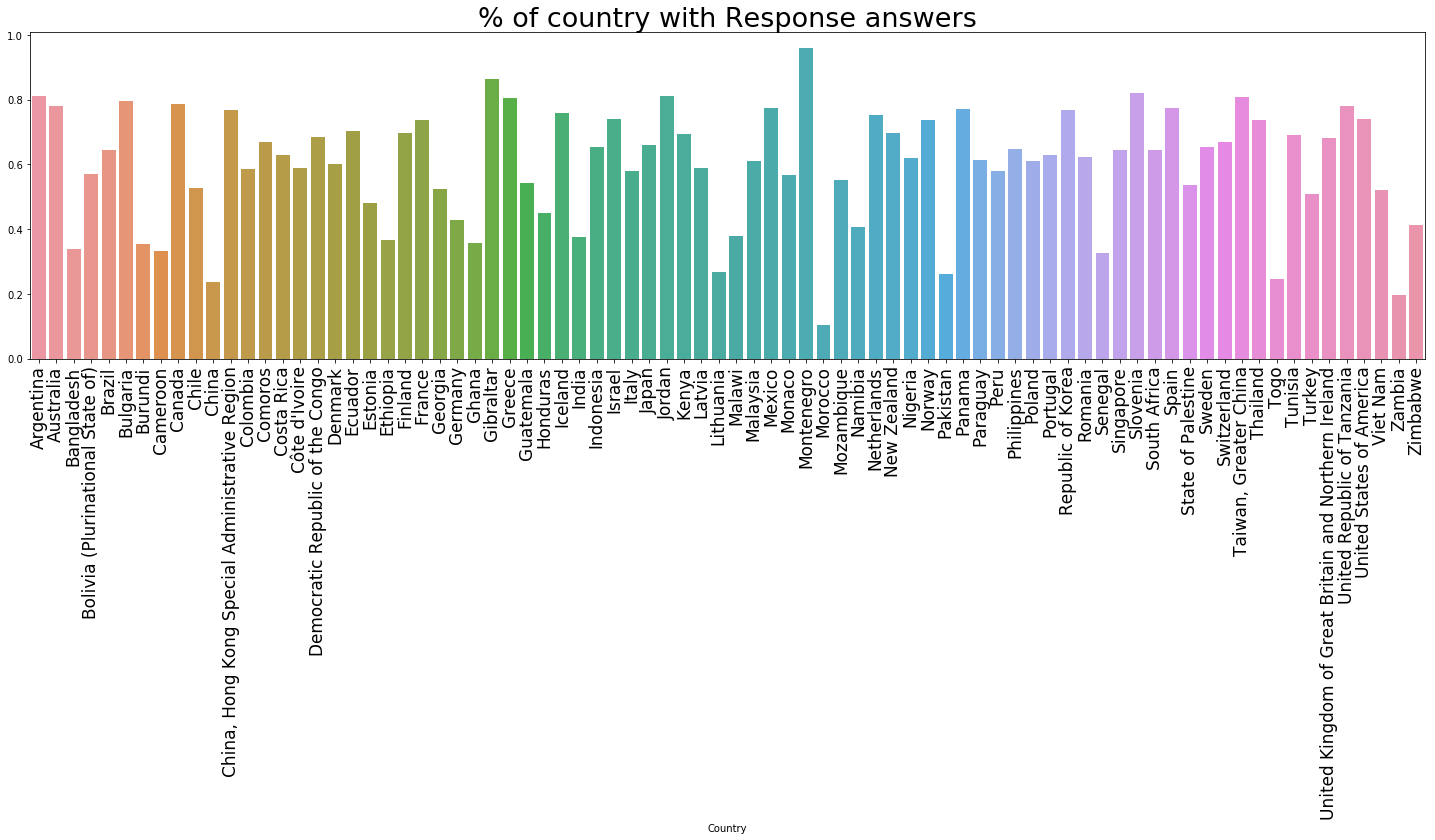

In [18]:
plt.figure(figsize=(25,6))
df2 = df_city_resp_18['Response Answer']
df_ha_ratio = df_city_resp_18[df2 != 'No Response'].groupby(['Country']).size()/df_city_resp_18.groupby(['Country']).size()
ax = sns.barplot(x=df_ha_ratio.index, y=df_ha_ratio)
ax.set_title("% of country with Response answers", fontsize = 27)
plt.xticks(rotation=90, fontsize = 17);
plt.show()

## Climate Hazards

Climatic hazards are agents of disaster in terms of what they may do to human settlements or to the environment. Potentially hazardous atmospheric phenomena include tropical cyclones, thunderstorms, tornadoes, drought, rain, hail, snow, lightning, fog, wind, temperature extremes, air pollution, and climatic change.
In the given dataset the information regarding climatic hazards that have already occured in the country is taken in account along with other intuitive factors and scales.

In [140]:
print("Top 2 important questions asked with respect to climatic hazard:".upper())
df_city_resp_18[df_city_resp_18['Section'] == 'Climate Hazards']['Question Name'].value_counts()[:2]

TOP 2 IMPORTANT QUESTIONS ASKED WITH RESPECT TO CLIMATIC HAZARD:


Please list the most significant climate hazards faced by your city and indicate the probability and consequence of these hazards, as well as the expected future change in frequency and intensity.  Please also select the top 3 assets or services that are affected by the climate hazard, and provide a description of the impact.    22880
Please identify the factors that most greatly affect your city’s ability to adapt to climate change, and indicate how those factors either enhance or challenge this ability.                                                                                                                                                               3894
Name: Question Name, dtype: int64

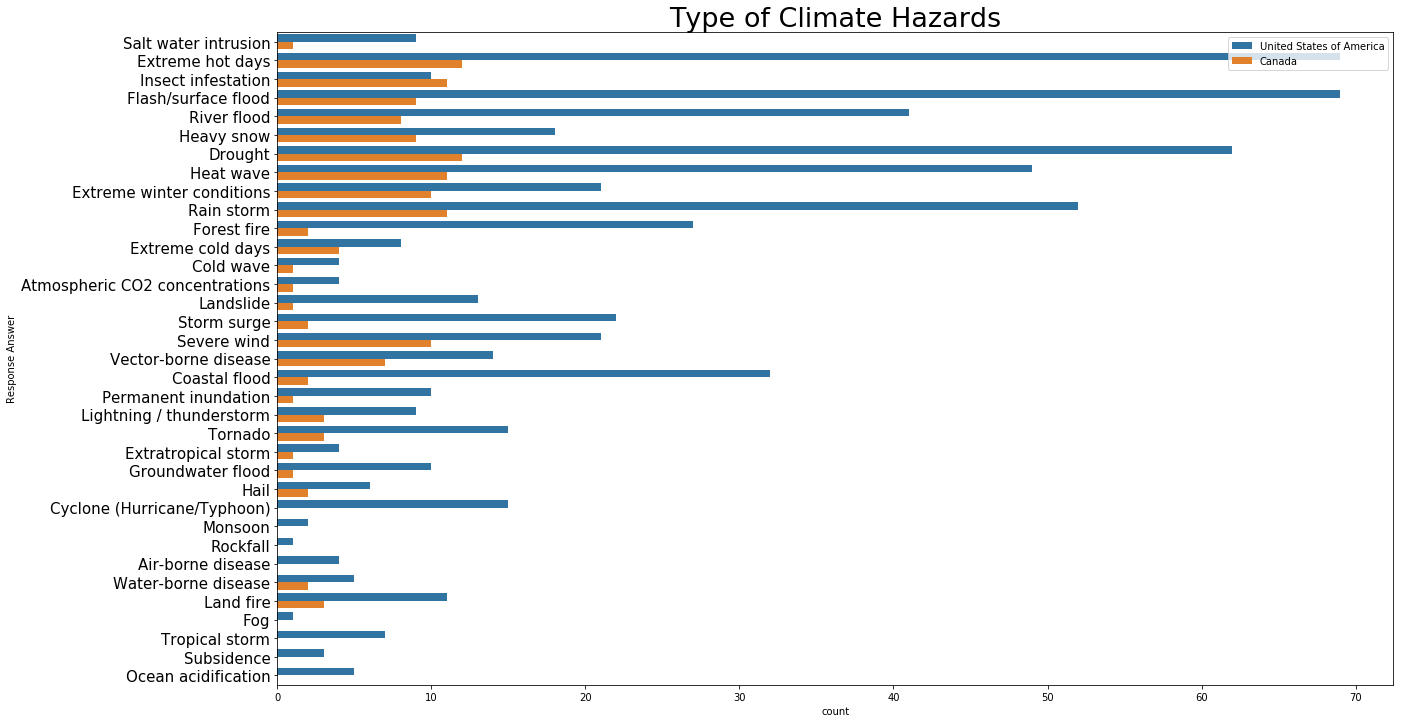

In [153]:
temp = df_city_resp_18[(df_city_resp_18['Section'] == 'Climate Hazards') & 
               (df_city_resp_18['Column Name'] == 'Climate Hazards')
                      & (df_city_resp_18['CDP Region'] == 'North America')].copy()

plt.rcParams['figure.figsize'] = (20, 12)

ax = sns.countplot(y = 'Response Answer', hue = 'Country', data = temp)
ax.set_title("Type of Climate Hazards", fontsize = 27)
plt.legend(loc = 'upper right', bbox_to_anchor = (1,1))
plt.yticks(fontsize = 15)
plt.show()

Above figure specifies the types of climatic hazards that have occured before or during 2018 in North America CDP Region as per the data

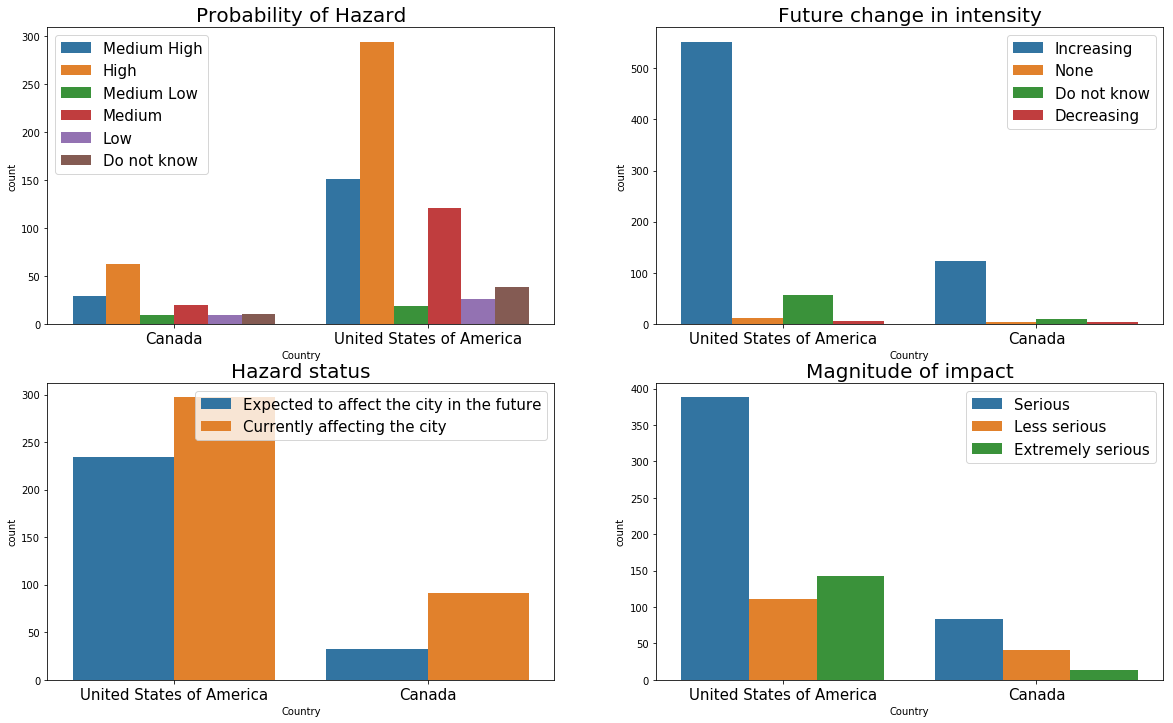

In [147]:
plt.rcParams['figure.figsize'] = (20, 12)
plt.subplot(2,2,1)
temp = df_city_resp_18[(df_city_resp_18['Section'] == 'Climate Hazards') & 
               (df_city_resp_18['Column Name'] == 'Probability of hazard')
                      & (df_city_resp_18['CDP Region'] == 'North America')].copy()
ax = sns.countplot(x = 'Country', hue = 'Response Answer', data = temp)
ax.set_title("Probability of Hazard", fontsize = 20)
plt.legend(loc = 'upper left', fontsize = 15)
plt.xticks(fontsize = 15)

plt.subplot(2,2,2)
temp = df_city_resp_18[(df_city_resp_18['Section'] == 'Climate Hazards') & 
               (df_city_resp_18['Column Name'] == 'Future change in intensity')
                      & (df_city_resp_18['CDP Region'] == 'North America')].copy()
ax = sns.countplot(x = 'Country', hue = 'Response Answer', data = temp)
ax.set_title("Future change in intensity", fontsize = 20)
plt.legend(loc = 'upper right', fontsize = 15)
plt.xticks(fontsize = 15)

plt.subplot(2,2,3)
temp = df_city_resp_18[(df_city_resp_18['Section'] == 'Climate Hazards') & 
               (df_city_resp_18['Column Name'] == 'Hazard status')
                      & (df_city_resp_18['CDP Region'] == 'North America')].copy()
ax = sns.countplot(x = 'Country', hue = 'Response Answer', data = temp)
ax.set_title("Hazard status", fontsize = 20)
plt.legend(loc = 'upper right', fontsize = 15)
plt.xticks(fontsize = 15)

plt.subplot(2,2,4)
temp = df_city_resp_18[(df_city_resp_18['Section'] == 'Climate Hazards') & 
               (df_city_resp_18['Column Name'] == 'Magnitude of impact')
                      & (df_city_resp_18['CDP Region'] == 'North America')].copy()
ax = sns.countplot(x = 'Country', hue = 'Response Answer', data = temp)
ax.set_title("Magnitude of impact", fontsize = 20)
plt.legend(loc = 'upper right', fontsize = 15)
plt.xticks(fontsize = 15)
plt.show()

For each hazard faced by the the region,
First and Third graph represents if the hazard that has already taken place is likely to hit the region again and with what intensity.
While Second plot depicts the probability of hazard to occure in future.
Fourth graph tells the intensity with which the hazard hit the region presently or in past.
All the above information inferences to the 1st question in climate section.

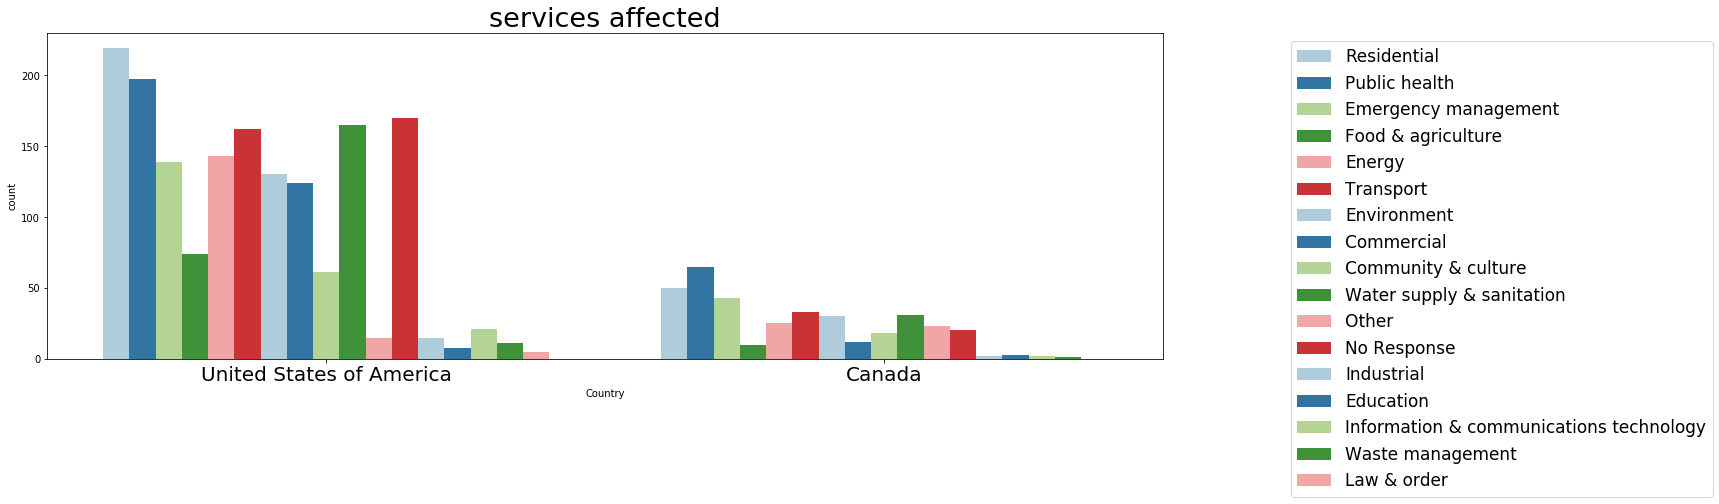

In [35]:
temp = df_city_resp_18[(df_city_resp_18['Section'] == 'Climate Hazards') & 
               (df_city_resp_18['Column Name'] == 'Top three assets/ services affected')
                      & (df_city_resp_18['CDP Region'] == 'North America')].copy()

plt.rcParams['figure.figsize'] = (20, 6)

ax = sns.countplot(x = 'Country', hue = 'Response Answer', data = temp, palette=sns.color_palette('Paired'))
ax.set_title("services affected", fontsize = 27)
plt.legend(bbox_to_anchor = (1.5, 1), loc = 'upper right', fontsize = 17)
plt.xticks(fontsize = 20)
plt.show()

This plot shows the services that are most affected by the climatic hazard that took place in Region

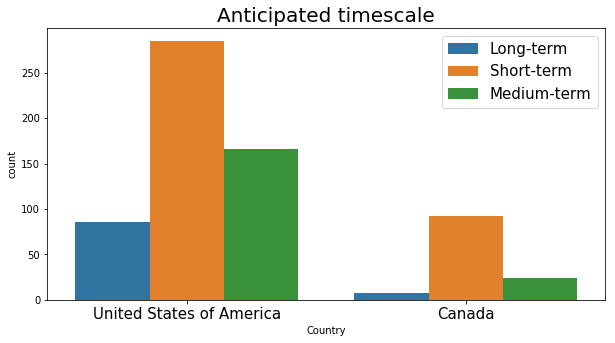

In [156]:
temp = df_city_resp_18[(df_city_resp_18['Section'] == 'Climate Hazards') & 
               (df_city_resp_18['Column Name'] == 'Anticipated timescale')
                      & (df_city_resp_18['CDP Region'] == 'North America')].copy()

plt.rcParams['figure.figsize'] = (10, 5)

ax = sns.countplot(x = 'Country', hue = 'Response Answer', data = temp)
ax.set_title("Anticipated timescale", fontsize = 20)
plt.legend(loc = 'upper right', fontsize = 15)
plt.xticks(fontsize = 15)
plt.show()

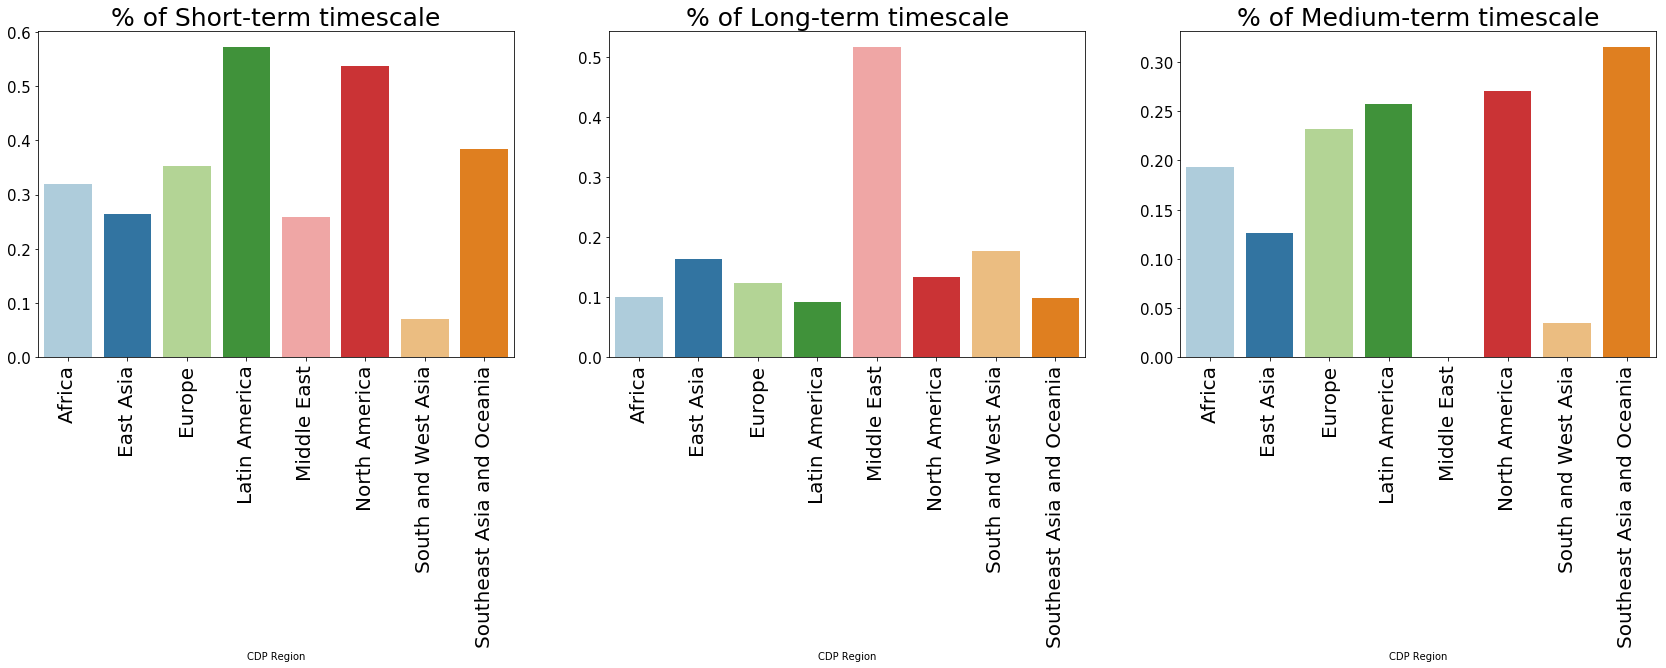

In [159]:
plt.rcParams['figure.figsize'] = (29, 6)

df_ha_ratio = df_city_resp_18[(df_city_resp_18['Section'] == 'Climate Hazards') & 
               (df_city_resp_18['Column Name'] == 'Anticipated timescale') & 
               (df_city_resp_18['Response Answer'] == 'Short-term')].groupby(['CDP Region']).size()/df_city_resp_18.groupby(['CDP Region']).size()*100

plt.subplot(1,3,1)
ax = sns.barplot(x=df_ha_ratio.index, y=df_ha_ratio,  palette="Paired")
ax.set_title("% of Short-term timescale", fontsize = 25)
plt.xticks(rotation = 90, fontsize = 20)
plt.yticks(fontsize = 15)

plt.subplot(1,3,2)
df_ha_ratio = df_city_resp_18[(df_city_resp_18['Section'] == 'Climate Hazards') & 
               (df_city_resp_18['Column Name'] == 'Anticipated timescale') & 
               (df_city_resp_18['Response Answer'] == 'Long-term')].groupby(['CDP Region']).size()/df_city_resp_18.groupby(['CDP Region']).size()*100
ax = sns.barplot(x=df_ha_ratio.index, y=df_ha_ratio,  palette="Paired")
ax.set_title("% of Long-term timescale", fontsize = 25)
plt.xticks(rotation = 90, fontsize = 20)
plt.yticks(fontsize = 15)

plt.subplot(1,3,3)
df_ha_ratio = df_city_resp_18[(df_city_resp_18['Section'] == 'Climate Hazards') & 
               (df_city_resp_18['Column Name'] == 'Anticipated timescale') & 
               (df_city_resp_18['Response Answer'] == 'Medium-term')].groupby(['CDP Region']).size()/df_city_resp_18.groupby(['CDP Region']).size()*100
ax = sns.barplot(x=df_ha_ratio.index, y=df_ha_ratio,  palette="Paired")
ax.set_title("% of Medium-term timescale", fontsize = 25)
plt.xticks(rotation = 90, fontsize = 20)
plt.yticks(fontsize = 15)
plt.show()

Above graph tells the percentage of Short-term, Long-term and Medium-term Timescale for each CDP Region.
Middle east is more prone to suffer from long term climatic hazard as compared to medium term hazard whereas Latin America is more prone to suffer from short term hazard as compared to long term hazard

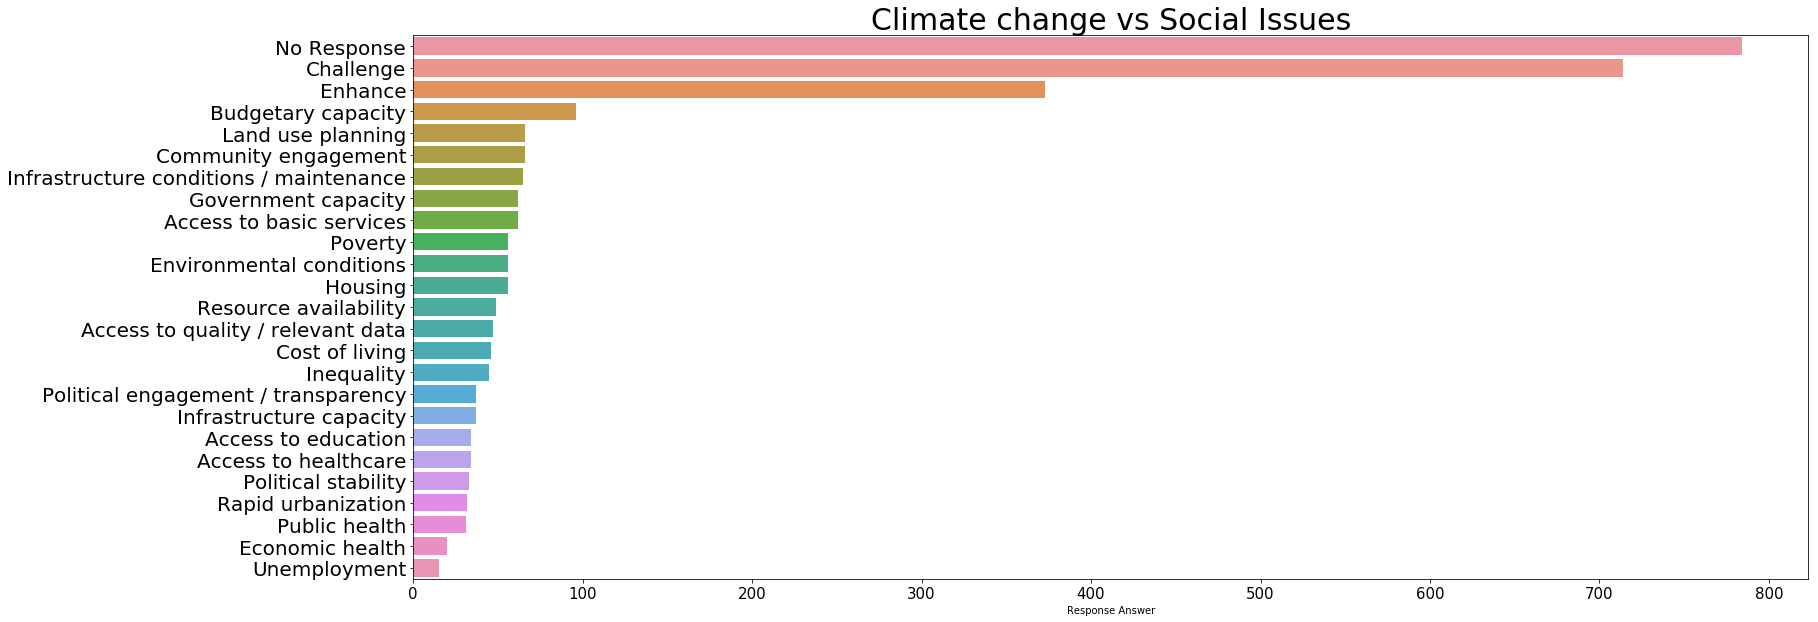

In [42]:
plt.figure(figsize=(25,10))
tempX = df_city_resp_18[df_city_resp_18['Question Number'] == '2.4']['Response Answer'].value_counts()[:25]
tempY = df_city_resp_18[df_city_resp_18['Question Number'] == '2.4']['Response Answer'].value_counts()[:25].index
ax = sns.barplot(x = tempX, y = tempY)
ax.set_title("Climate change vs Social Issues", fontsize = 30)
plt.xticks(fontsize = 15);
plt.yticks(fontsize = 20)
plt.show()

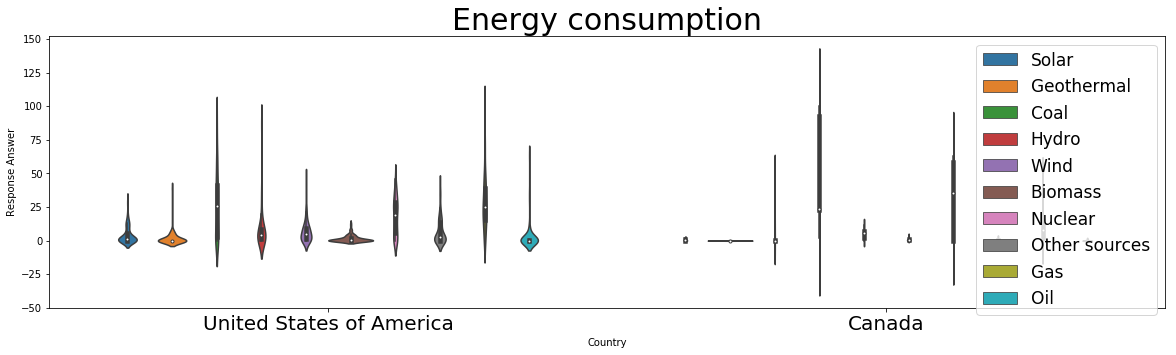

In [45]:
temp = df_city_resp_18[(df_city_resp_18['Section'] == 'Energy') 
              & (df_city_resp_18['Row Name'] == 'Energy consumption percentage')
                      & (df_city_resp_18['CDP Region'] == 'North America')].copy()

plt.rcParams['figure.figsize'] = (20, 5)
temp = temp[temp['Response Answer'] != 'No Response']
temp = temp[temp['Response Answer'] != 'calculated field']
temp['Response Answer'] = pd.to_numeric(temp['Response Answer'], downcast = "float")

ax = sns.violinplot(x = 'Country', y = 'Response Answer', hue = 'Column Name', data = temp)
plt.title("Energy consumption", fontsize = 30, fontweight = 10)
plt.legend(loc = 'upper right', fontsize = 17)
plt.xticks(fontsize = 20)
plt.show()

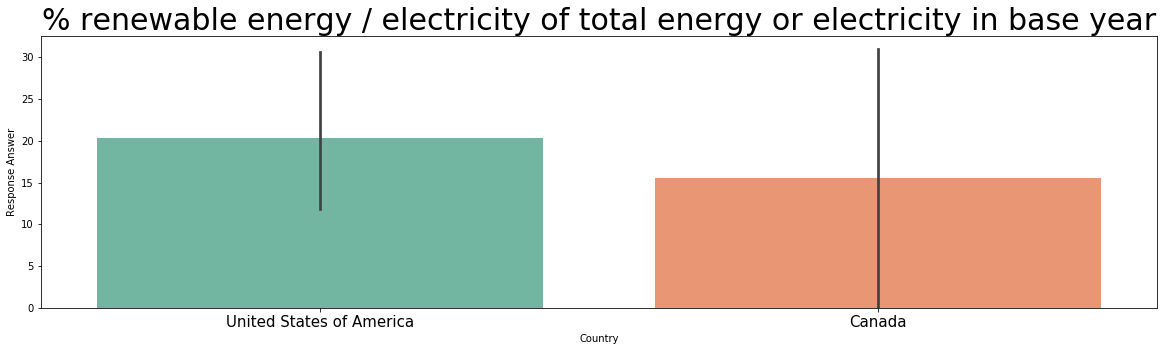

In [47]:
temp = df_city_resp_18[(df_city_resp_18['Section'] == 'Energy') 
  & (df_city_resp_18['Column Name'] == 'Percentage renewable energy / electricity of total energy or electricity in base year')
                      & (df_city_resp_18['CDP Region'] == 'North America')].copy()

plt.rcParams['figure.figsize'] = (20, 5)
temp = temp[temp['Response Answer'] != 'No Response']
temp['Response Answer'] = pd.to_numeric(temp['Response Answer'], downcast = "float")
ax = sns.barplot(x = 'Country', y = 'Response Answer', data = temp, palette=sns.color_palette("Set2"))

ax.set_title("% renewable energy / electricity of total energy or electricity in base year", fontsize = 30)
plt.xticks(fontsize = 15);
plt.show()

# EMISSION

Scope 1 covers direct emissions from owned or controlled sources. Scope 2 covers indirect emissions from the generation of purchased electricity, steam, heating and cooling consumed by the reporting company. Scope 3 includes all other indirect emissions that occur in a company's value chain.

In [54]:
# Breaking the city responses dataset into 2 parts
# one carrying information about climate hazard and othe about scope 1 emission breakdown 
# and then merging the data on account number as common field

t1 = df_city_resp_18[(df_city_resp_18['Section'] == 'Climate Hazards') 
       & (df_city_resp_18['Column Name'] == 'Climate Hazards')].copy()
t2 = df_city_resp_18[(df_city_resp_18['CDP Region'] == 'North America')
       & (df_city_resp_18['Section'] == 'Scope 1 Emissions Breakdown')].copy()

sc1df = pd.merge(t2, t1[['Response Answer', 'Account Number']], on='Account Number', how='inner')
sc1df.drop_duplicates(subset=None, keep="first", inplace=True)
sc1df.rename(columns={'Response Answer_y': 'type', 'Response Answer_x': 'Answer'}, inplace=True)
sc1df.drop(['Questionnaire', 'Year Reported to CDP', 'Comments', 'File Name', 'Last update'], axis = 1, inplace = True)

## Scope 1 Emissions Breakdown

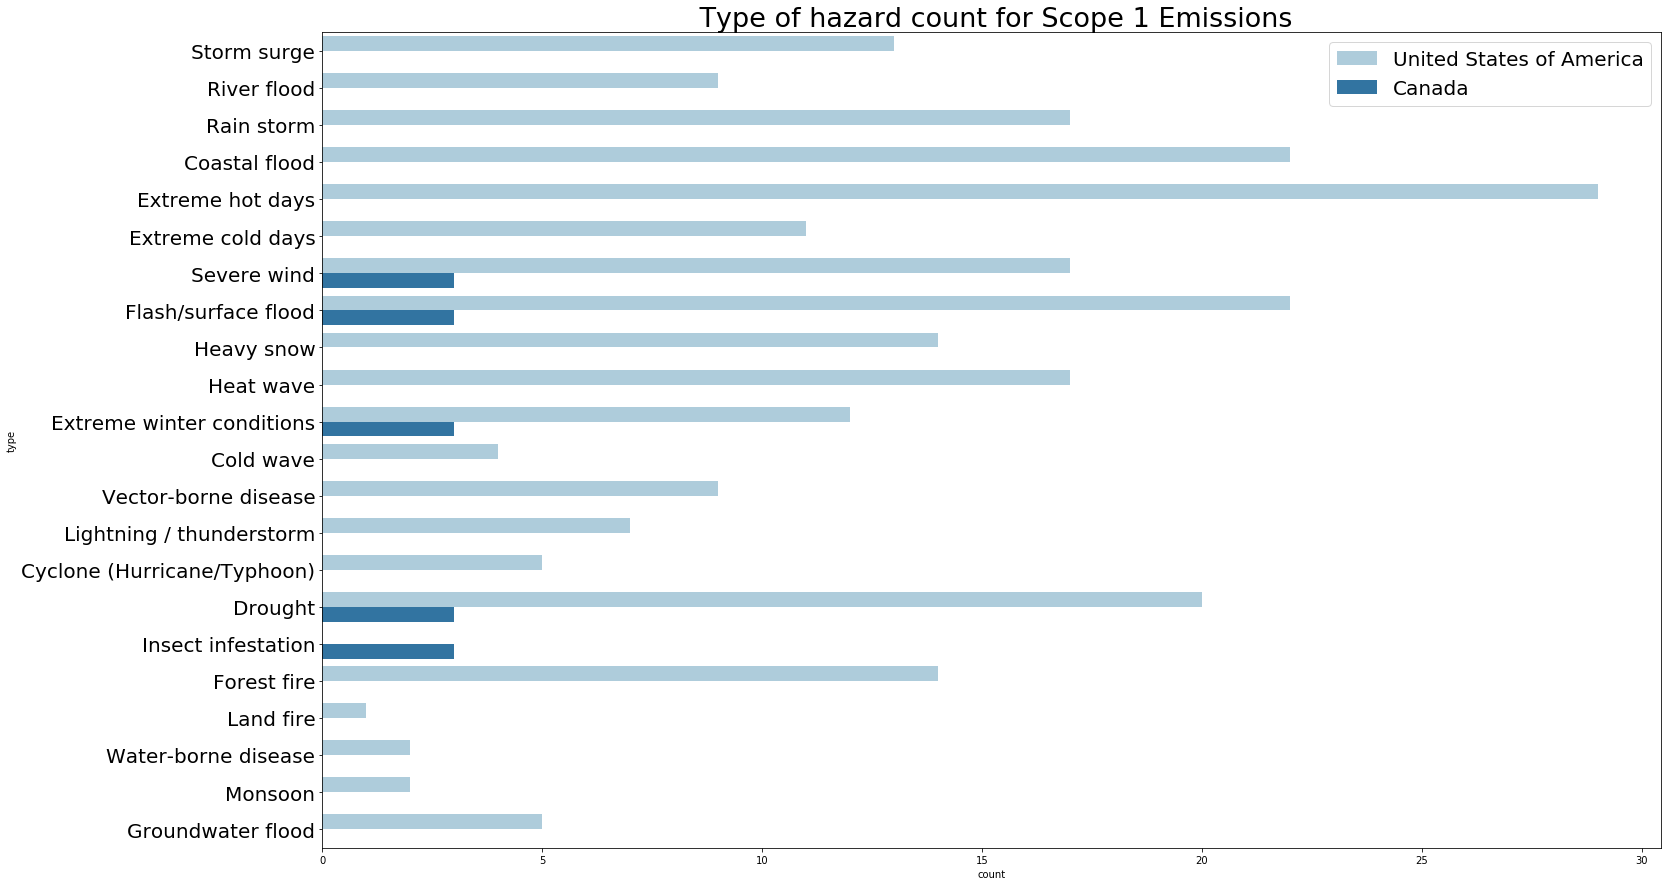

In [82]:
plt.rcParams['figure.figsize'] = (24, 15)
temp = sc1df[ (sc1df['Answer'] != 'No Response')
             & (sc1df['type'] != 'No Response')
             & (sc1df['Column Name'] == 'Sector')].copy()

ax = sns.countplot(y = 'type', hue = 'Country', data = temp, palette=sns.color_palette("Paired"))
ax.set_title(" Type of hazard count for Scope 1 Emissions", fontsize = 27)
plt.yticks(fontsize = 20)
plt.legend(loc = 'upper right', fontsize = 20)
plt.show()

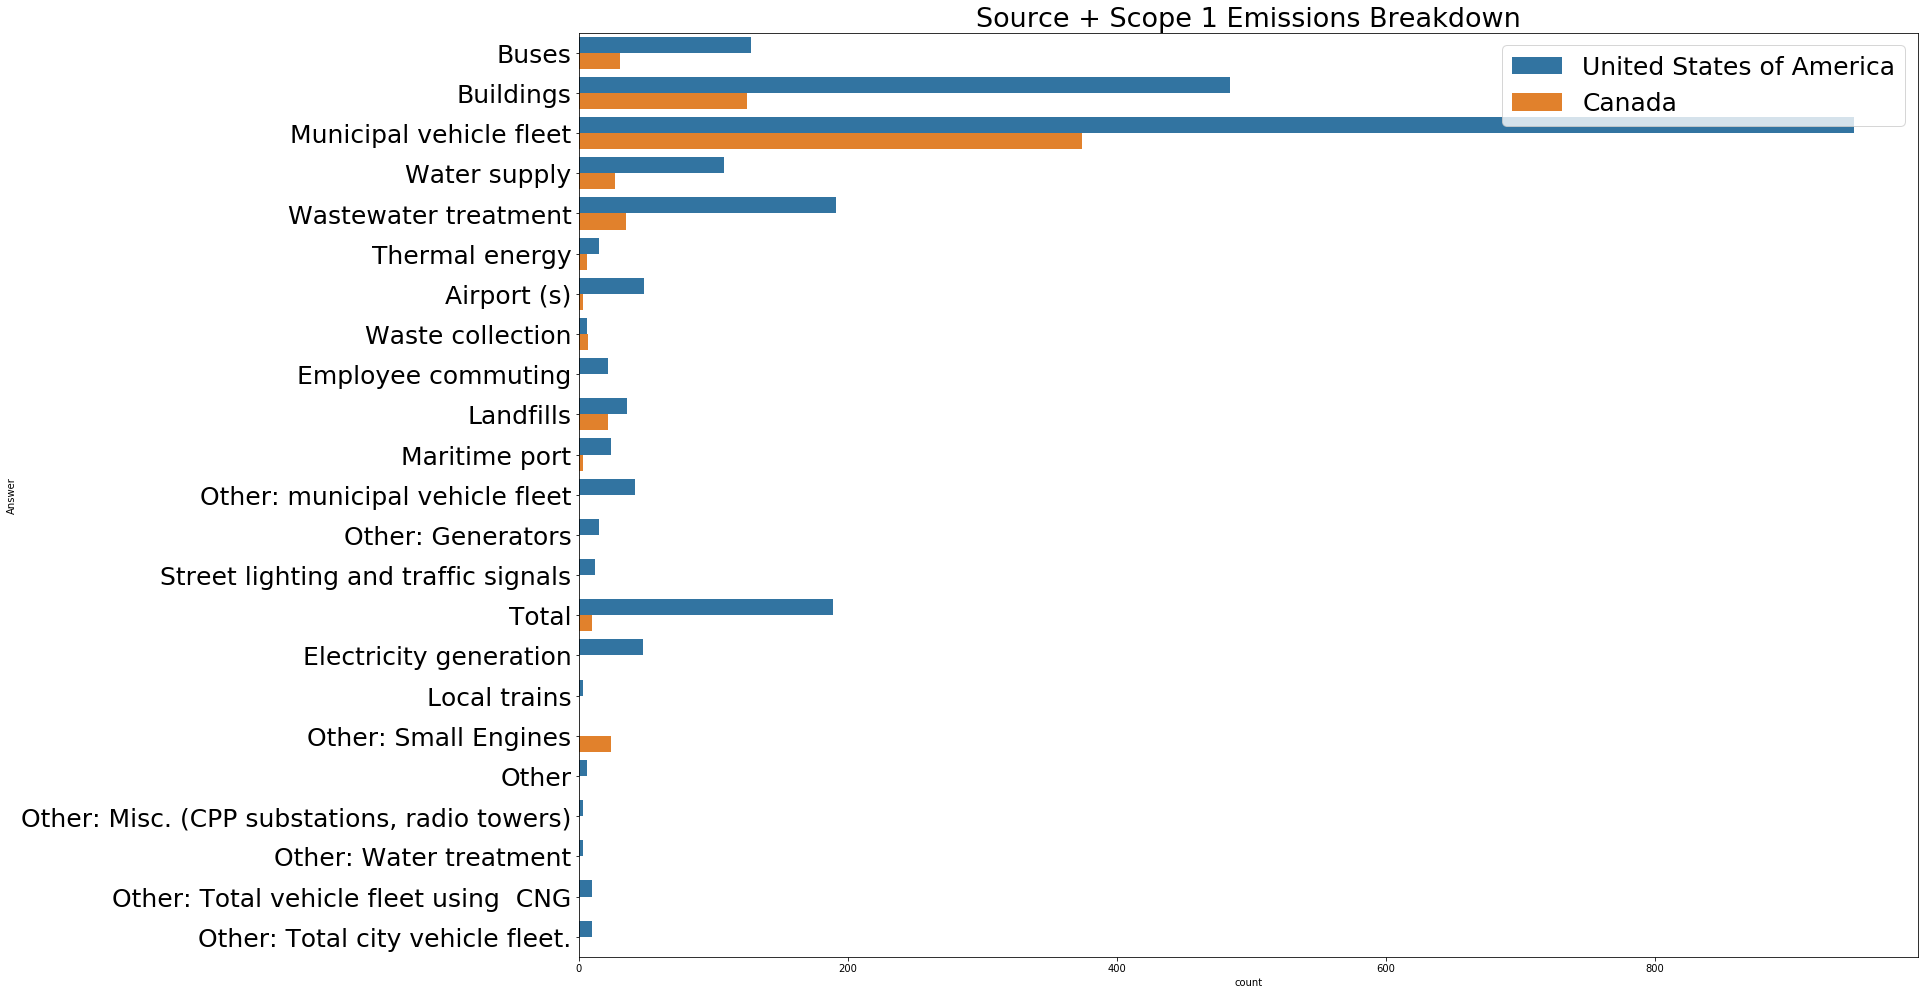

In [84]:
plt.rcParams['figure.figsize'] = (24, 17)
temp = sc1df[ (sc1df['Answer'] != 'No Response')
             & (sc1df['type'] != 'No Response')
             & (sc1df['Column Name'] == 'Source')].copy()

ax = sns.countplot(y = 'Answer', hue = 'Country', data = temp)
ax.set_title("Source + Scope 1 Emissions Breakdown", fontsize = 27)
plt.yticks(fontsize = 25)
plt.legend(loc = 'upper right', fontsize = 25)
plt.show()

Source of Scope 1 emission for North America CDP Region, Buildings along with Municipal vehicle fleet is considered to be most important factors in scope 1 emissions

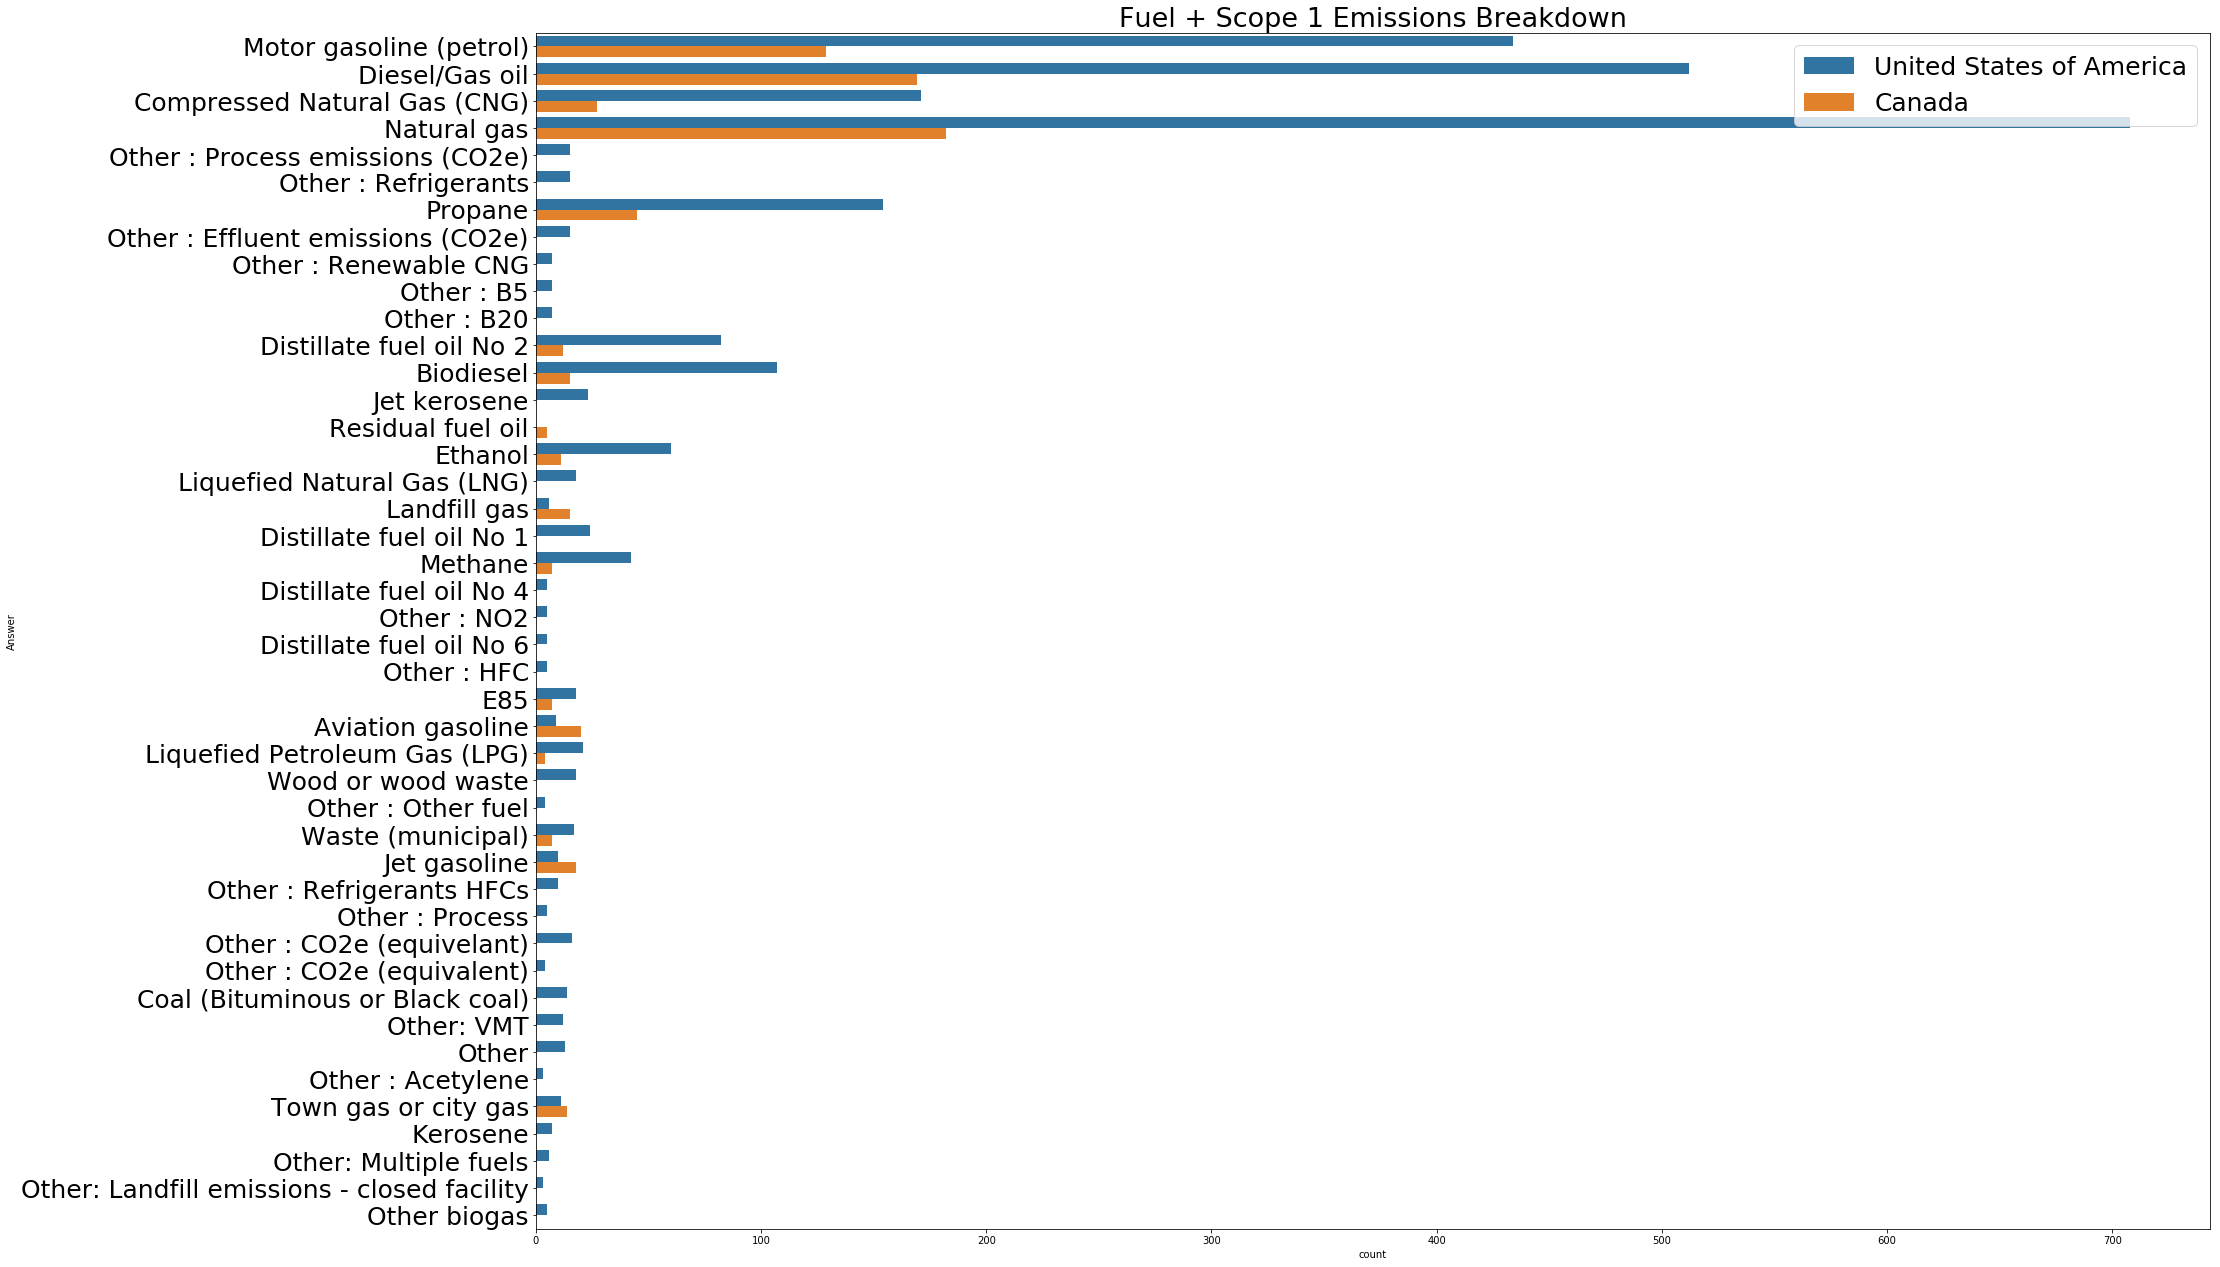

In [87]:
plt.rcParams['figure.figsize'] = (30, 22)
temp = sc1df[ (sc1df['Answer'] != 'No Response')
             & (sc1df['type'] != 'No Response')
             & (sc1df['Column Name'] == 'Fuel')].copy()

ax = sns.countplot(y = 'Answer', hue = 'Country', data = temp)
ax.set_title("Fuel + Scope 1 Emissions Breakdown", fontsize = 27)
plt.yticks( fontsize = 25)
plt.legend(loc = 'upper right ', fontsize = 25)
plt.show()

Natural Gas, Compressed natural and Gas oil or Diesel are most common Fuel with scope 1 emissions

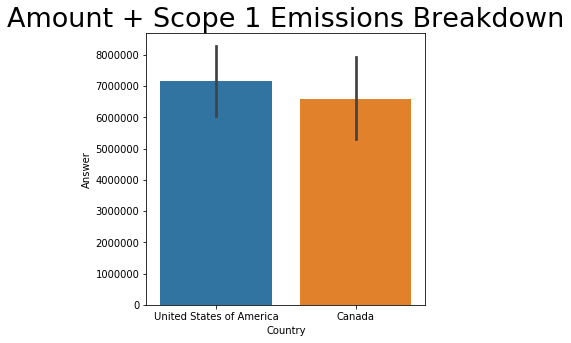

In [63]:
plt.rcParams['figure.figsize'] = (5, 5)
temp = sc1df[ (sc1df['Answer'] != 'No Response')
             & (sc1df['Column Name'] == 'Amount')].copy()
temp['Answer'] = pd.to_numeric(temp['Answer'], downcast = "float")
ax = sns.barplot(x = 'Country', y = 'Answer', data = temp)
ax.set_title("Amount + Scope 1 Emissions Breakdown", fontsize = 27)
plt.show()

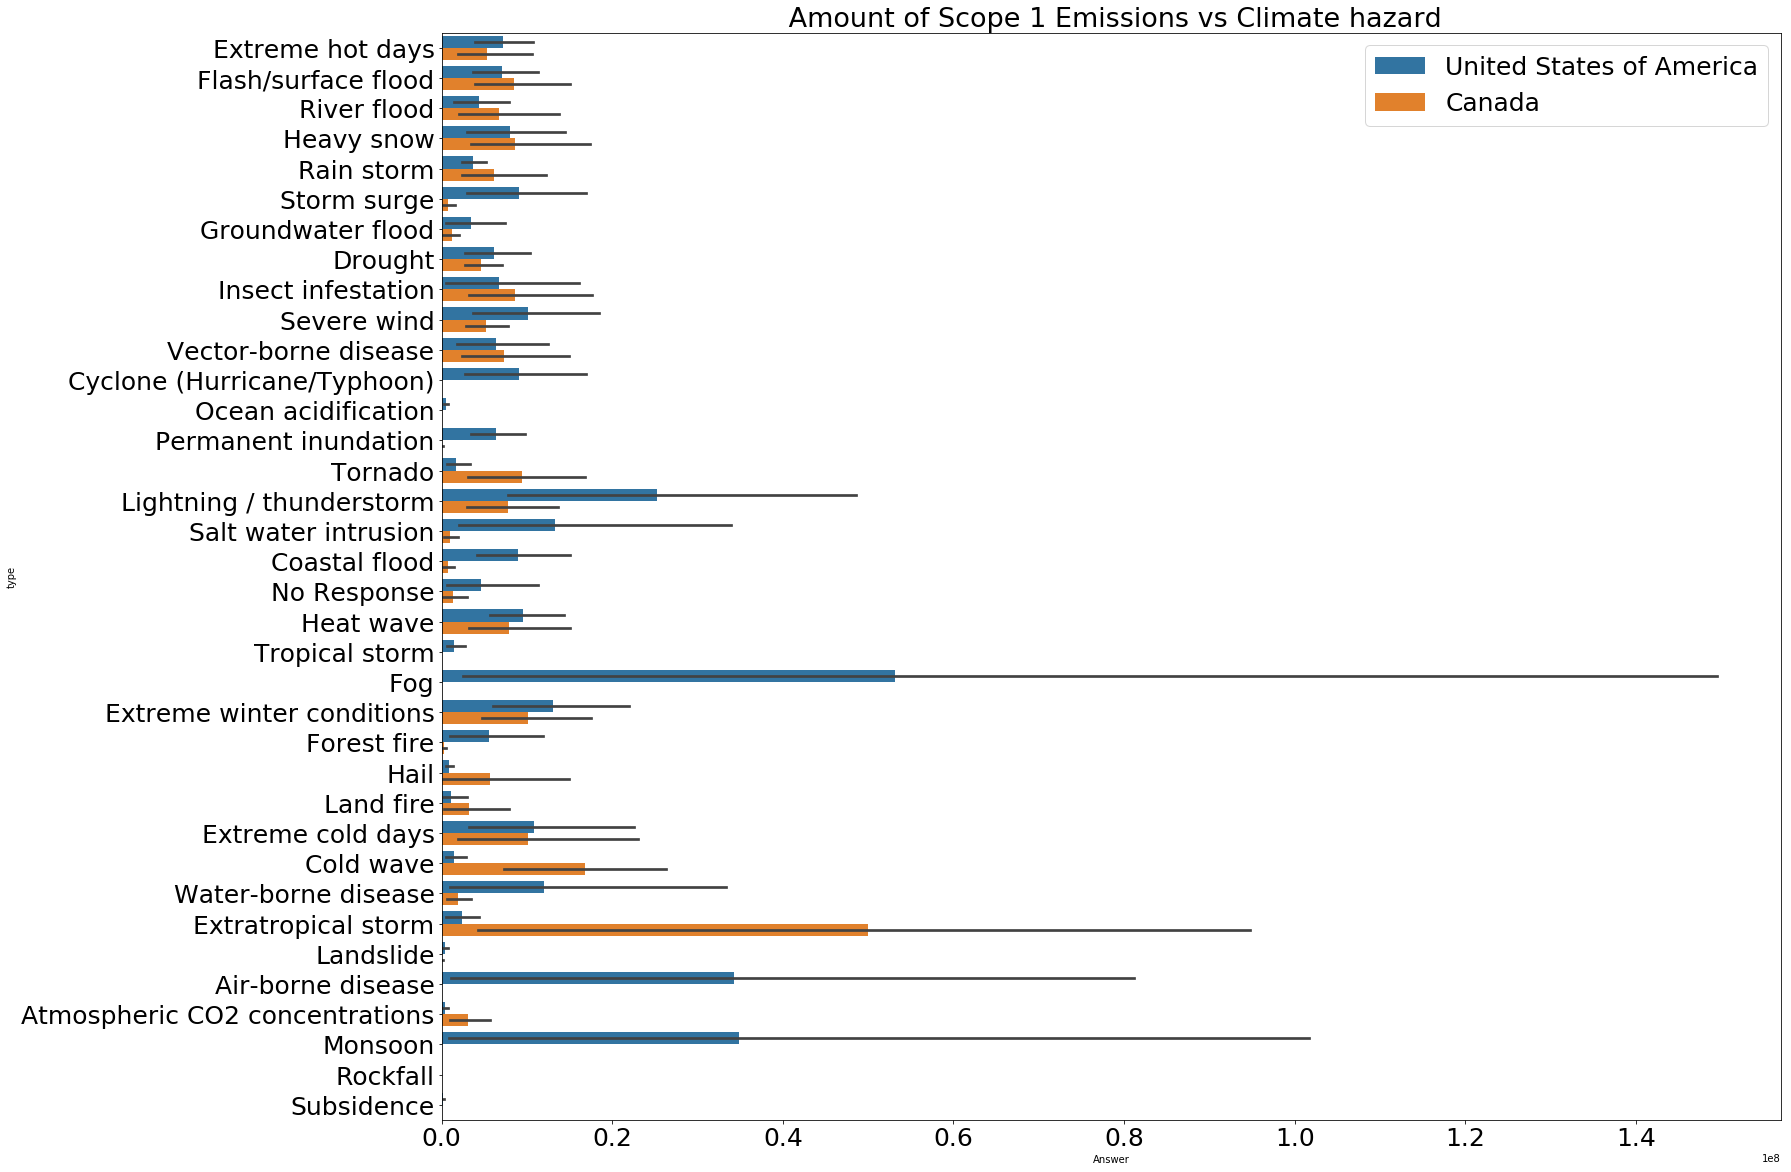

In [160]:
plt.rcParams['figure.figsize'] = (24, 20)
temp = sc1df[ (sc1df['Answer'] != 'No Response')
             & (sc1df['Column Name'] == 'Amount')].copy()

temp['Answer'] = pd.to_numeric(temp['Answer'], downcast = "float")
ax = sns.barplot(y = 'type', x = 'Answer', hue = 'Country', data = temp)
ax.set_title(" Amount of Scope 1 Emissions vs Climate hazard", fontsize = 27)
plt.yticks(fontsize = 25); plt.xticks(fontsize = 25)
plt.legend(loc = 'upper right', fontsize = 25)
plt.show()

Regions suffering from climatic hazards as Fog, Extratropical storm and Monsoon have highest value/amount of scope 1 emission

## Scope 2 Emissions Breakdown

In [65]:
t1 = df_city_resp_18[(df_city_resp_18['Section'] == 'Climate Hazards') 
       & (df_city_resp_18['Column Name'] == 'Climate Hazards')].copy()
t2 = df_city_resp_18[(df_city_resp_18['CDP Region'] == 'North America')
       & (df_city_resp_18['Section'] == 'Scope 2 Emissions Breakdown')].copy()

sc2df = pd.merge(t2, t1[['Response Answer', 'Account Number']], on='Account Number', how='inner')
sc2df.drop_duplicates(subset=None, keep="first", inplace=True)
sc2df.rename(columns={'Response Answer_y': 'type', 'Response Answer_x': 'Answer'}, inplace=True)
sc2df.drop(['Questionnaire', 'Year Reported to CDP', 'CDP Region', 'Comments', 'File Name', 'Last update'], axis = 1, inplace = True)

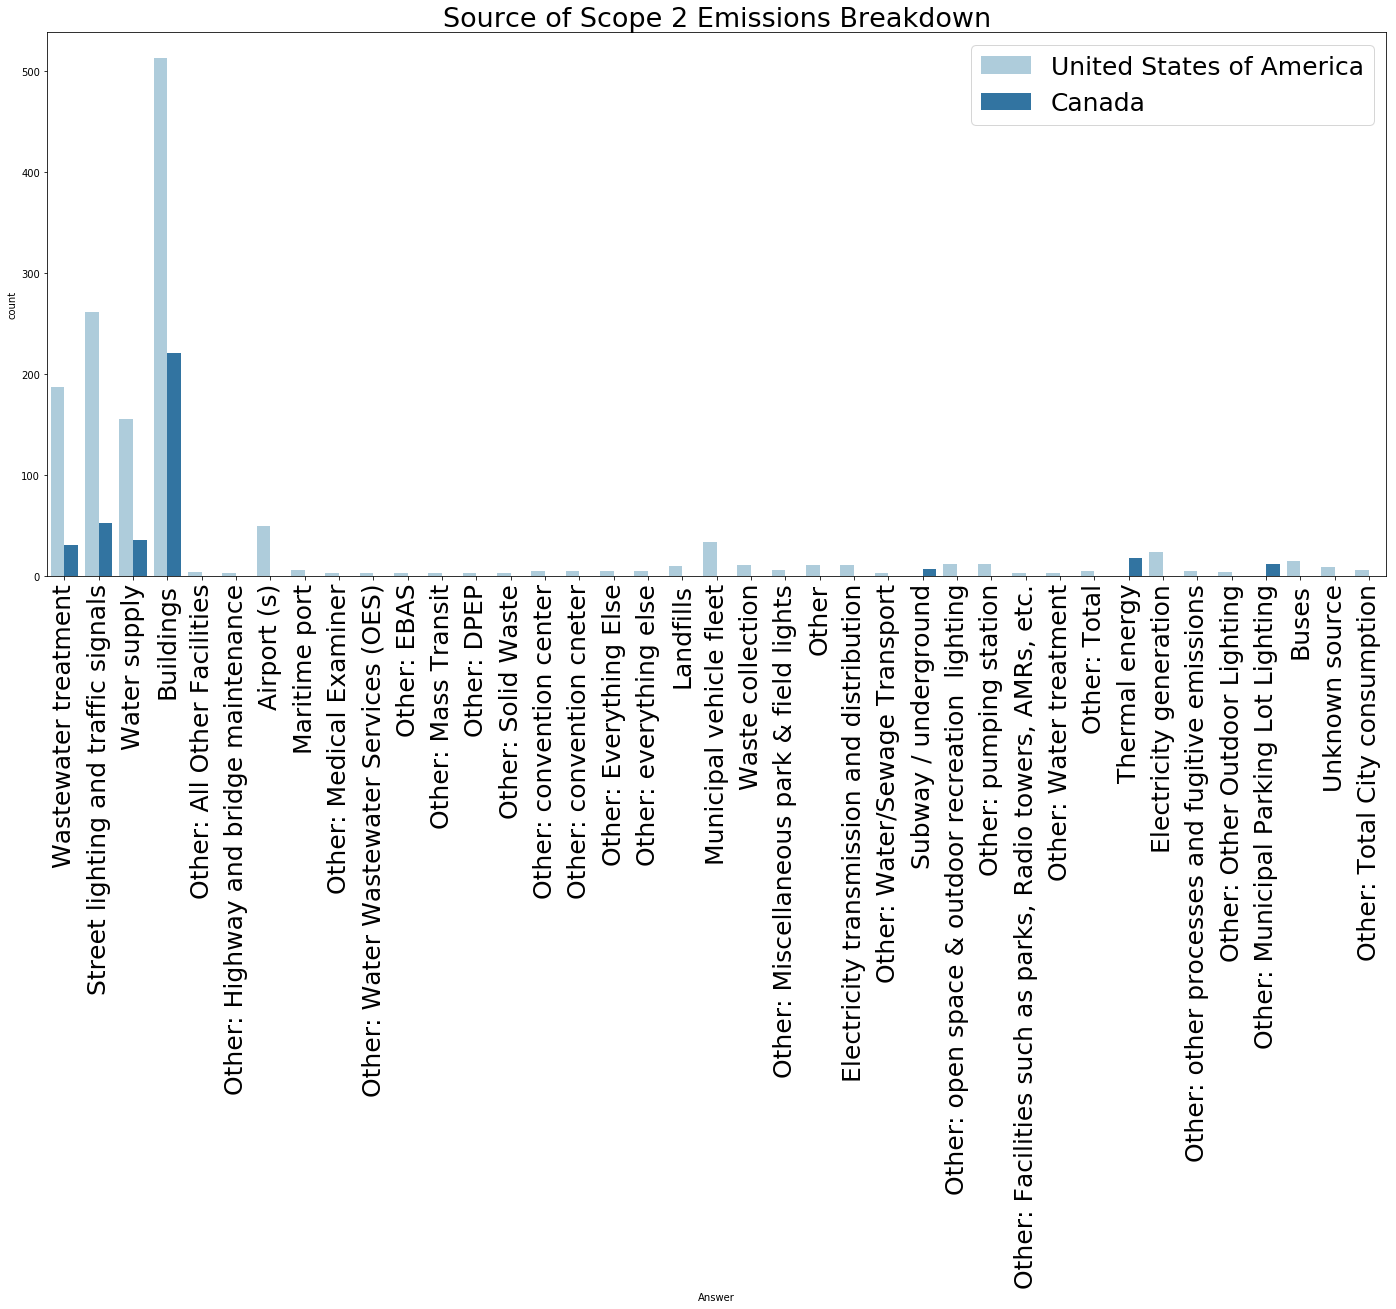

In [67]:
plt.rcParams['figure.figsize'] = (24, 10)
temp = sc2df[ (sc2df['Answer'] != 'No Response')
             & (sc2df['type'] != 'No Response')
             & (sc2df['Column Name'] == 'Source')].copy()

ax = sns.countplot(x = 'Answer', hue = 'Country', data = temp, palette=sns.color_palette("Paired"))
ax.set_title("Source of Scope 2 Emissions Breakdown", fontsize = 27)
plt.xticks(rotation = 90, fontsize = 25)
plt.legend(loc = 'upper right', fontsize = 25)
plt.show()

Buildings, water supply and traffic signals are most likely to be cause of scope 2 emission in both USA and Canada while Thermal energy and Parking lot lighting are mainly responsible for scope 2 emission in Canada while Airports and municipal vehicle fleet are resonsible for emission in USA only

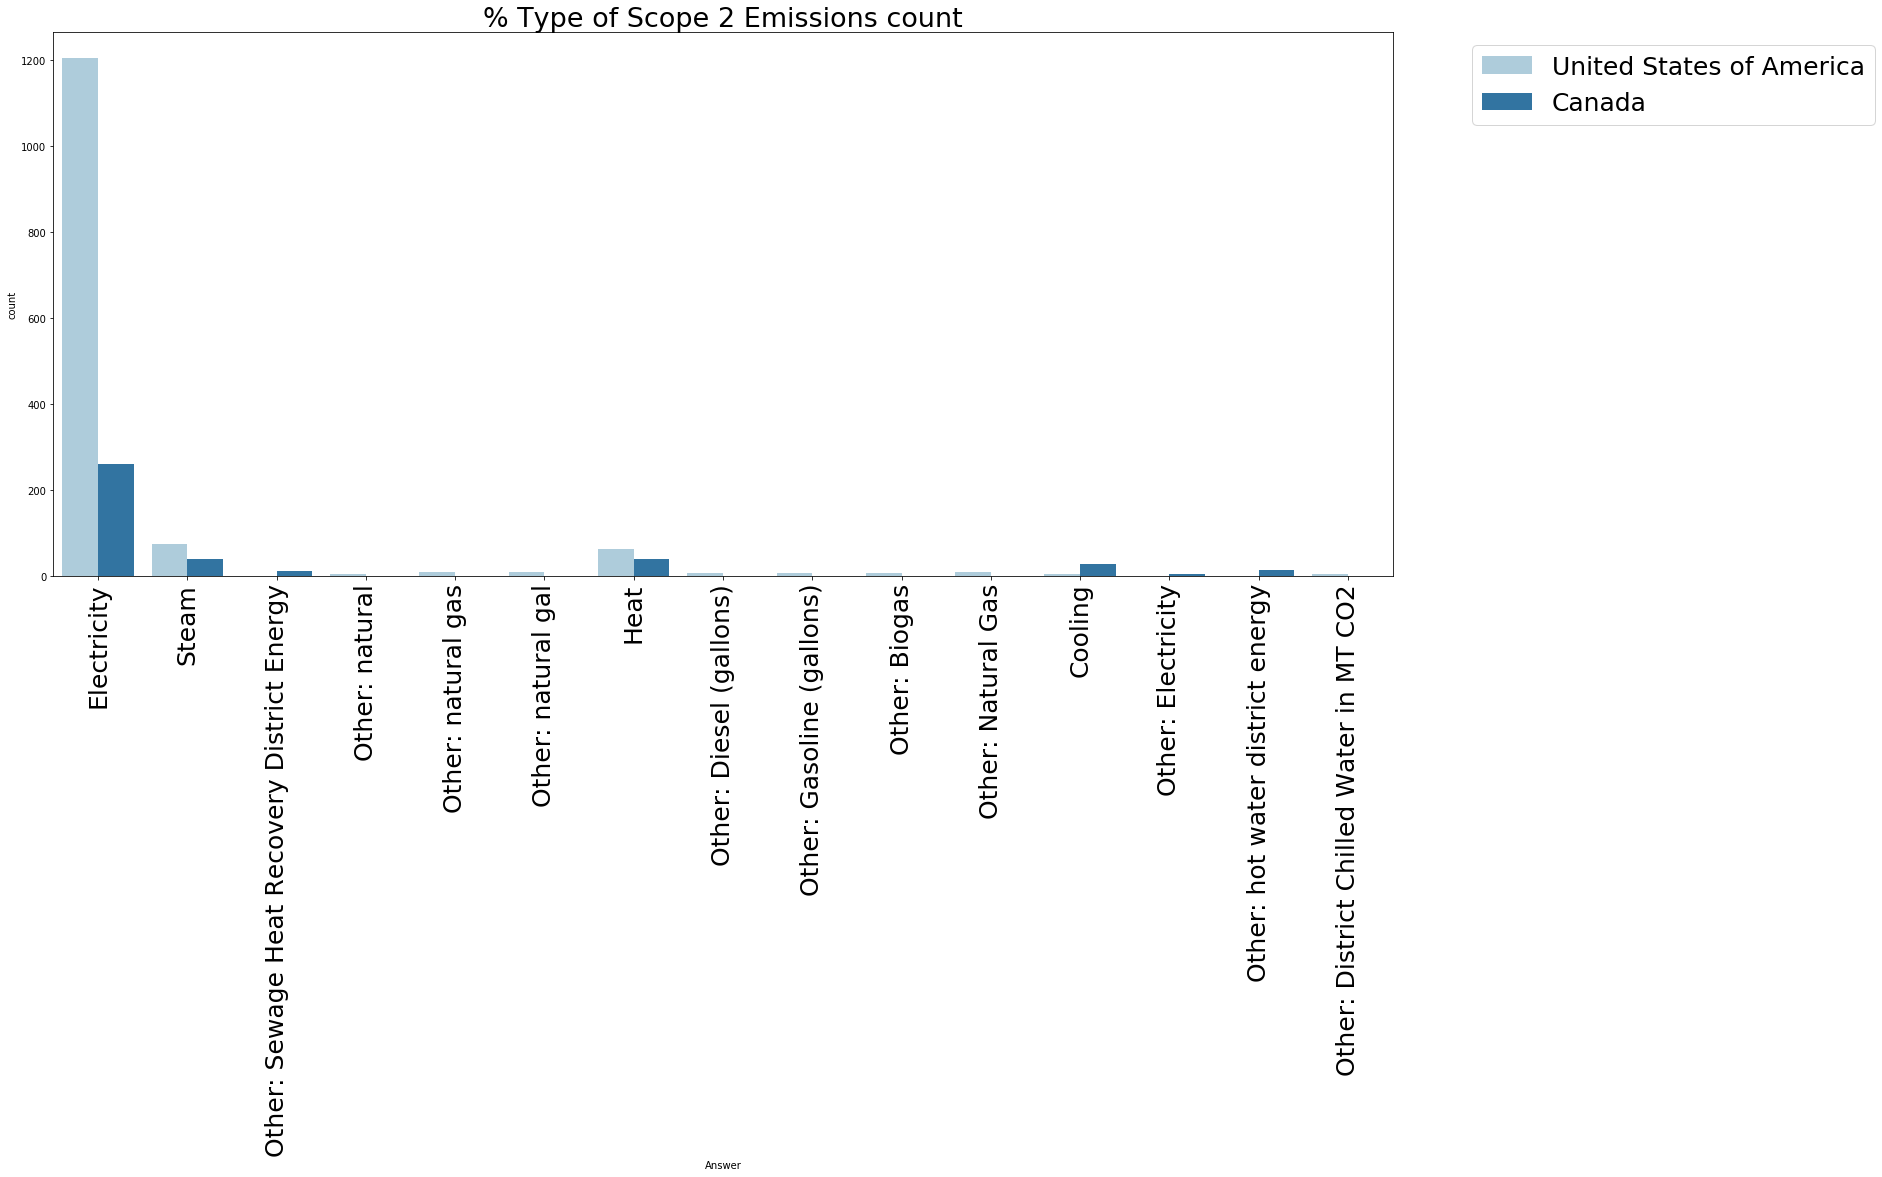

In [68]:
plt.rcParams['figure.figsize'] = (24, 10)
temp = sc2df[ (sc2df['Answer'] != 'No Response')
             & (sc2df['type'] != 'No Response')
             & (sc2df['Column Name'] == 'Type')].copy()

ax = sns.countplot(x = 'Answer', hue = 'Country', data = temp, palette=sns.color_palette("Paired"))
ax.set_title("% Type Scope 2 Emissions count", fontsize = 27)
plt.xticks(rotation = 90, fontsize = 25)
plt.legend(bbox_to_anchor = (1.05,1), fontsize = 25)
plt.show()

Electricity is a major reason of scope 2 emission, In Canada Cooling is more responsible for scope 2 emission

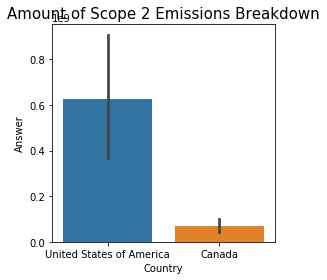

In [69]:
plt.rcParams['figure.figsize'] = (4, 4)
temp = sc2df[ (sc2df['Answer'] != 'No Response')
             & (sc2df['Column Name'] == 'Amount')].copy()
temp['Answer'] = pd.to_numeric(temp['Answer'], downcast = "float")
ax = sns.barplot(x = 'Country', y = 'Answer', data = temp)
ax.set_title("Amount of Scope 2 Emissions Breakdown", fontsize = 15)
plt.show()

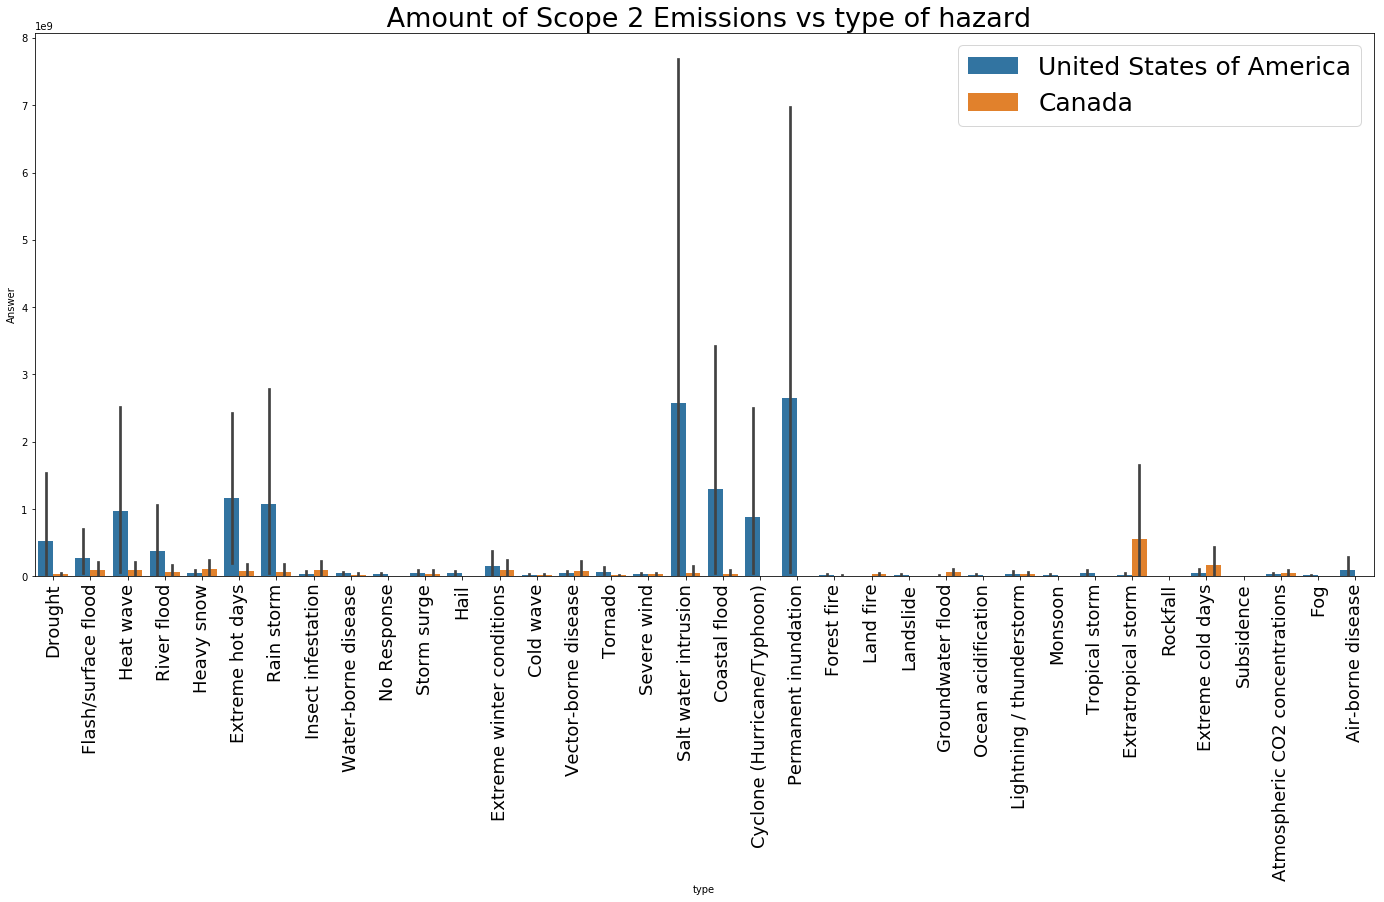

In [71]:
plt.rcParams['figure.figsize'] = (24, 10)
temp = sc2df[ (sc2df['Answer'] != 'No Response')
             & (sc2df['Column Name'] == 'Amount')].copy()

temp['Answer'] = pd.to_numeric(temp['Answer'], downcast = "float")
ax = sns.barplot(x = 'type', y = 'Answer', hue = 'Country', data = temp)
ax.set_title(" Amount of Scope 2 Emissions vs type of hazard", fontsize = 27)
plt.xticks(rotation = 90, fontsize = 18)
plt.legend(loc = 'upper right', fontsize = 25)
plt.show()

## GHG Emissions Data

Greenhouse gases are those that absorb and emit infrared radiation in the wavelength range emitted by Earth. Carbon dioxide (0.04%), nitrous oxide, methane and ozone are trace gases that account for almost 0.1% of Earth's atmosphere and have an appreciable greenhouse effect.

In [72]:
t1 = df_city_resp_18[(df_city_resp_18['Section'] == 'Climate Hazards') 
       & (df_city_resp_18['Column Name'] == 'Climate Hazards')].copy()
t2 = df_city_resp_18[(df_city_resp_18['CDP Region'] == 'North America')
       & (df_city_resp_18['Section'] == 'GHG Emissions Data')].copy()

ghgdf = pd.merge(t2, t1[['Response Answer', 'Account Number']], on='Account Number', how='inner')
ghgdf.drop_duplicates(subset=None, keep="first", inplace=True)
ghgdf.rename(columns={'Response Answer_y': 'type', 'Response Answer_x': 'Answer'}, inplace=True)
ghgdf.drop(['Questionnaire', 'Year Reported to CDP', 'CDP Region', 'Comments', 'File Name', 'Last update'], axis = 1, inplace = True)

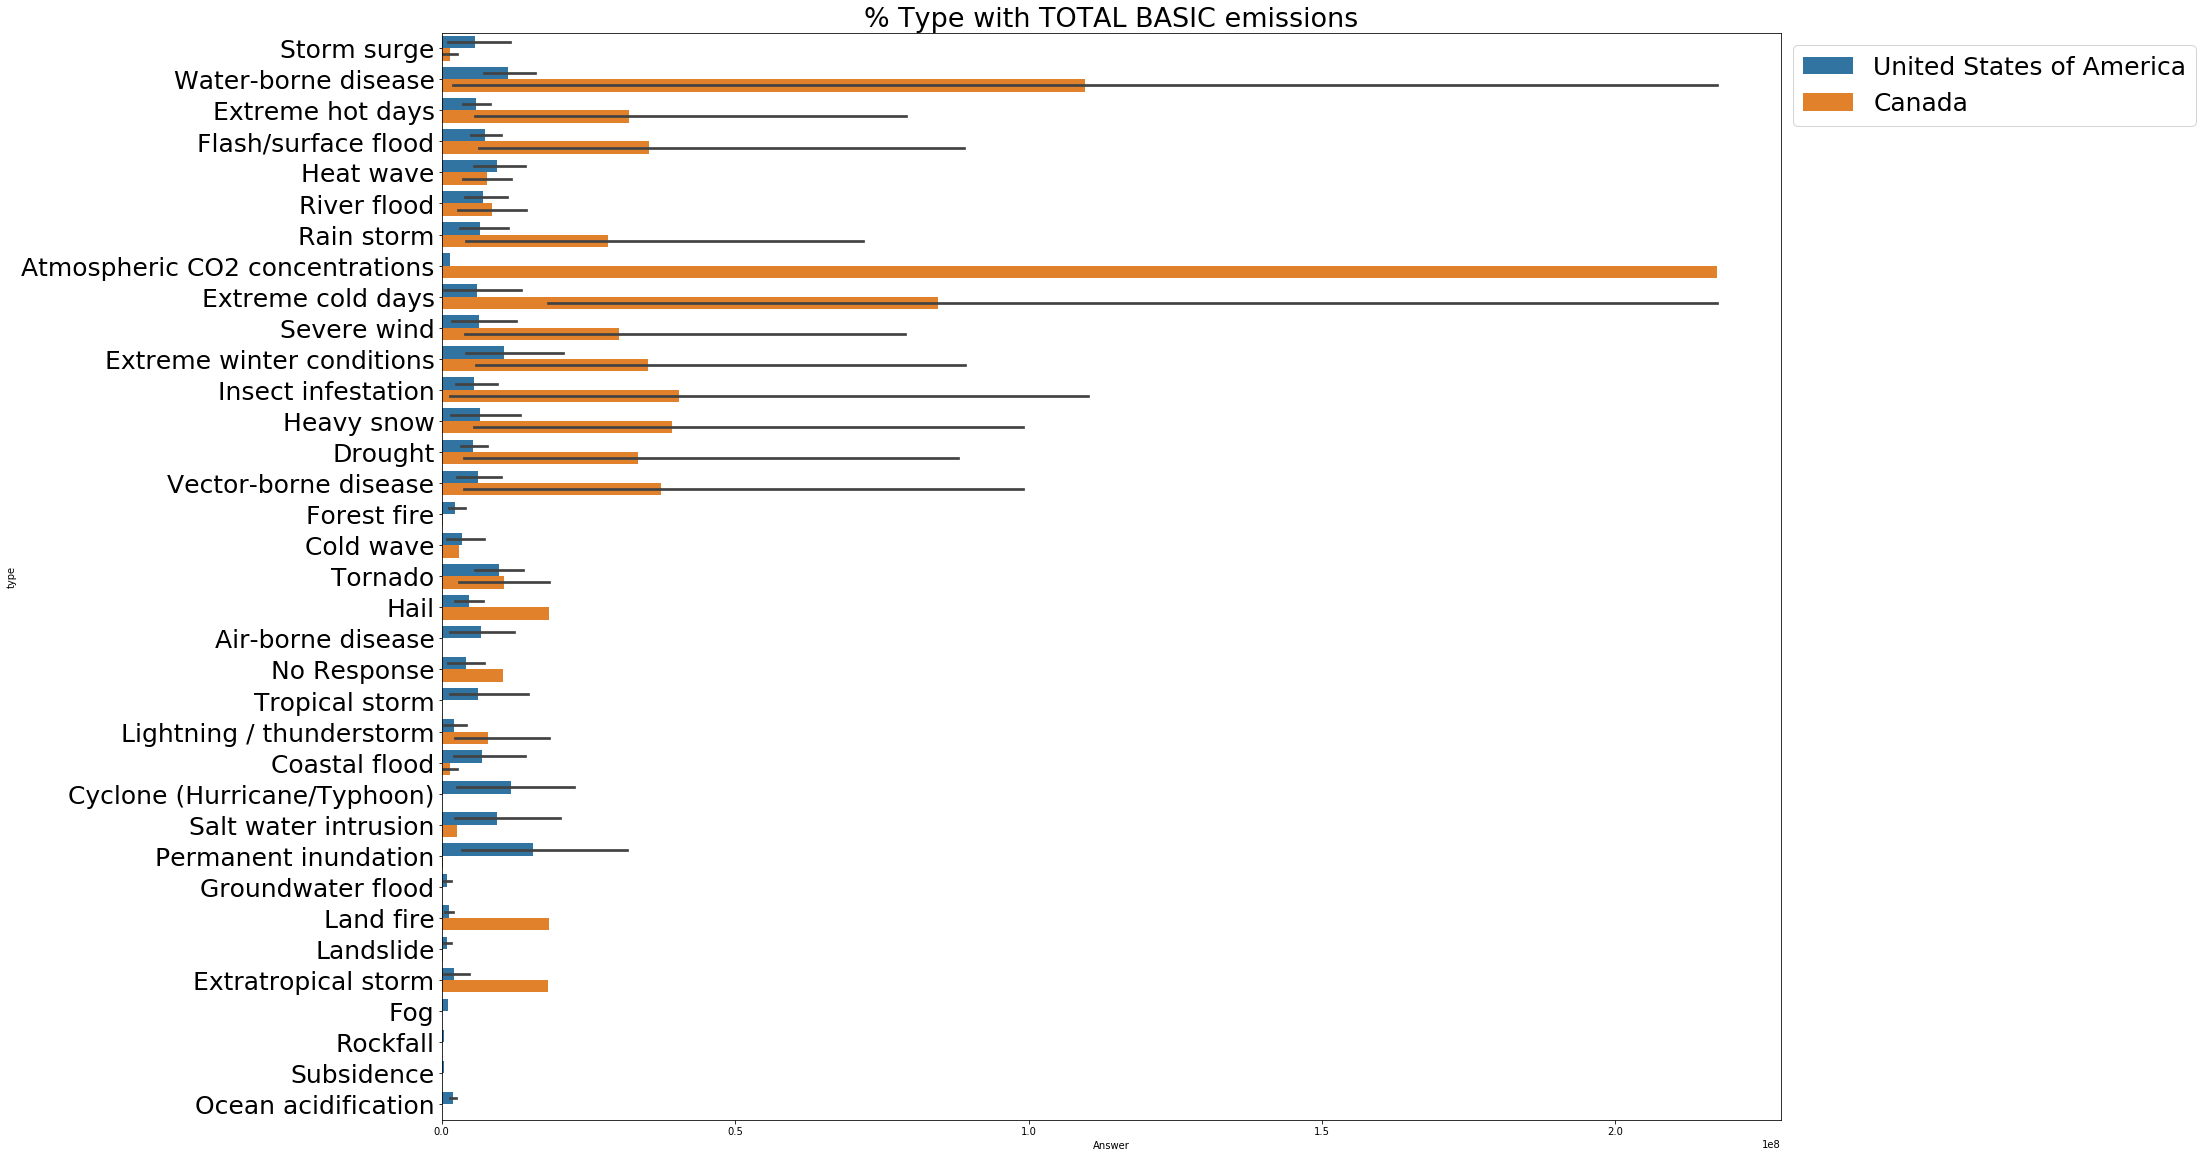

In [75]:
plt.rcParams['figure.figsize'] = (24, 20)
temp = ghgdf[ (ghgdf['Answer'] != 'No Response')
             & (ghgdf['Column Name'] == 'Emissions (metric tonnes CO2e)')
            & (ghgdf['Row Name'] == 'TOTAL BASIC emissions')].copy()

temp['Answer'] = pd.to_numeric(temp['Answer'], downcast = "float")
ax = sns.barplot(y = 'type', x = 'Answer', hue = 'Country', data = temp)
ax.set_title("% Type with TOTAL BASIC emissions", fontsize = 27)
plt.yticks(fontsize = 25)
plt.legend(bbox_to_anchor = (1,1), fontsize = 25)
plt.show()

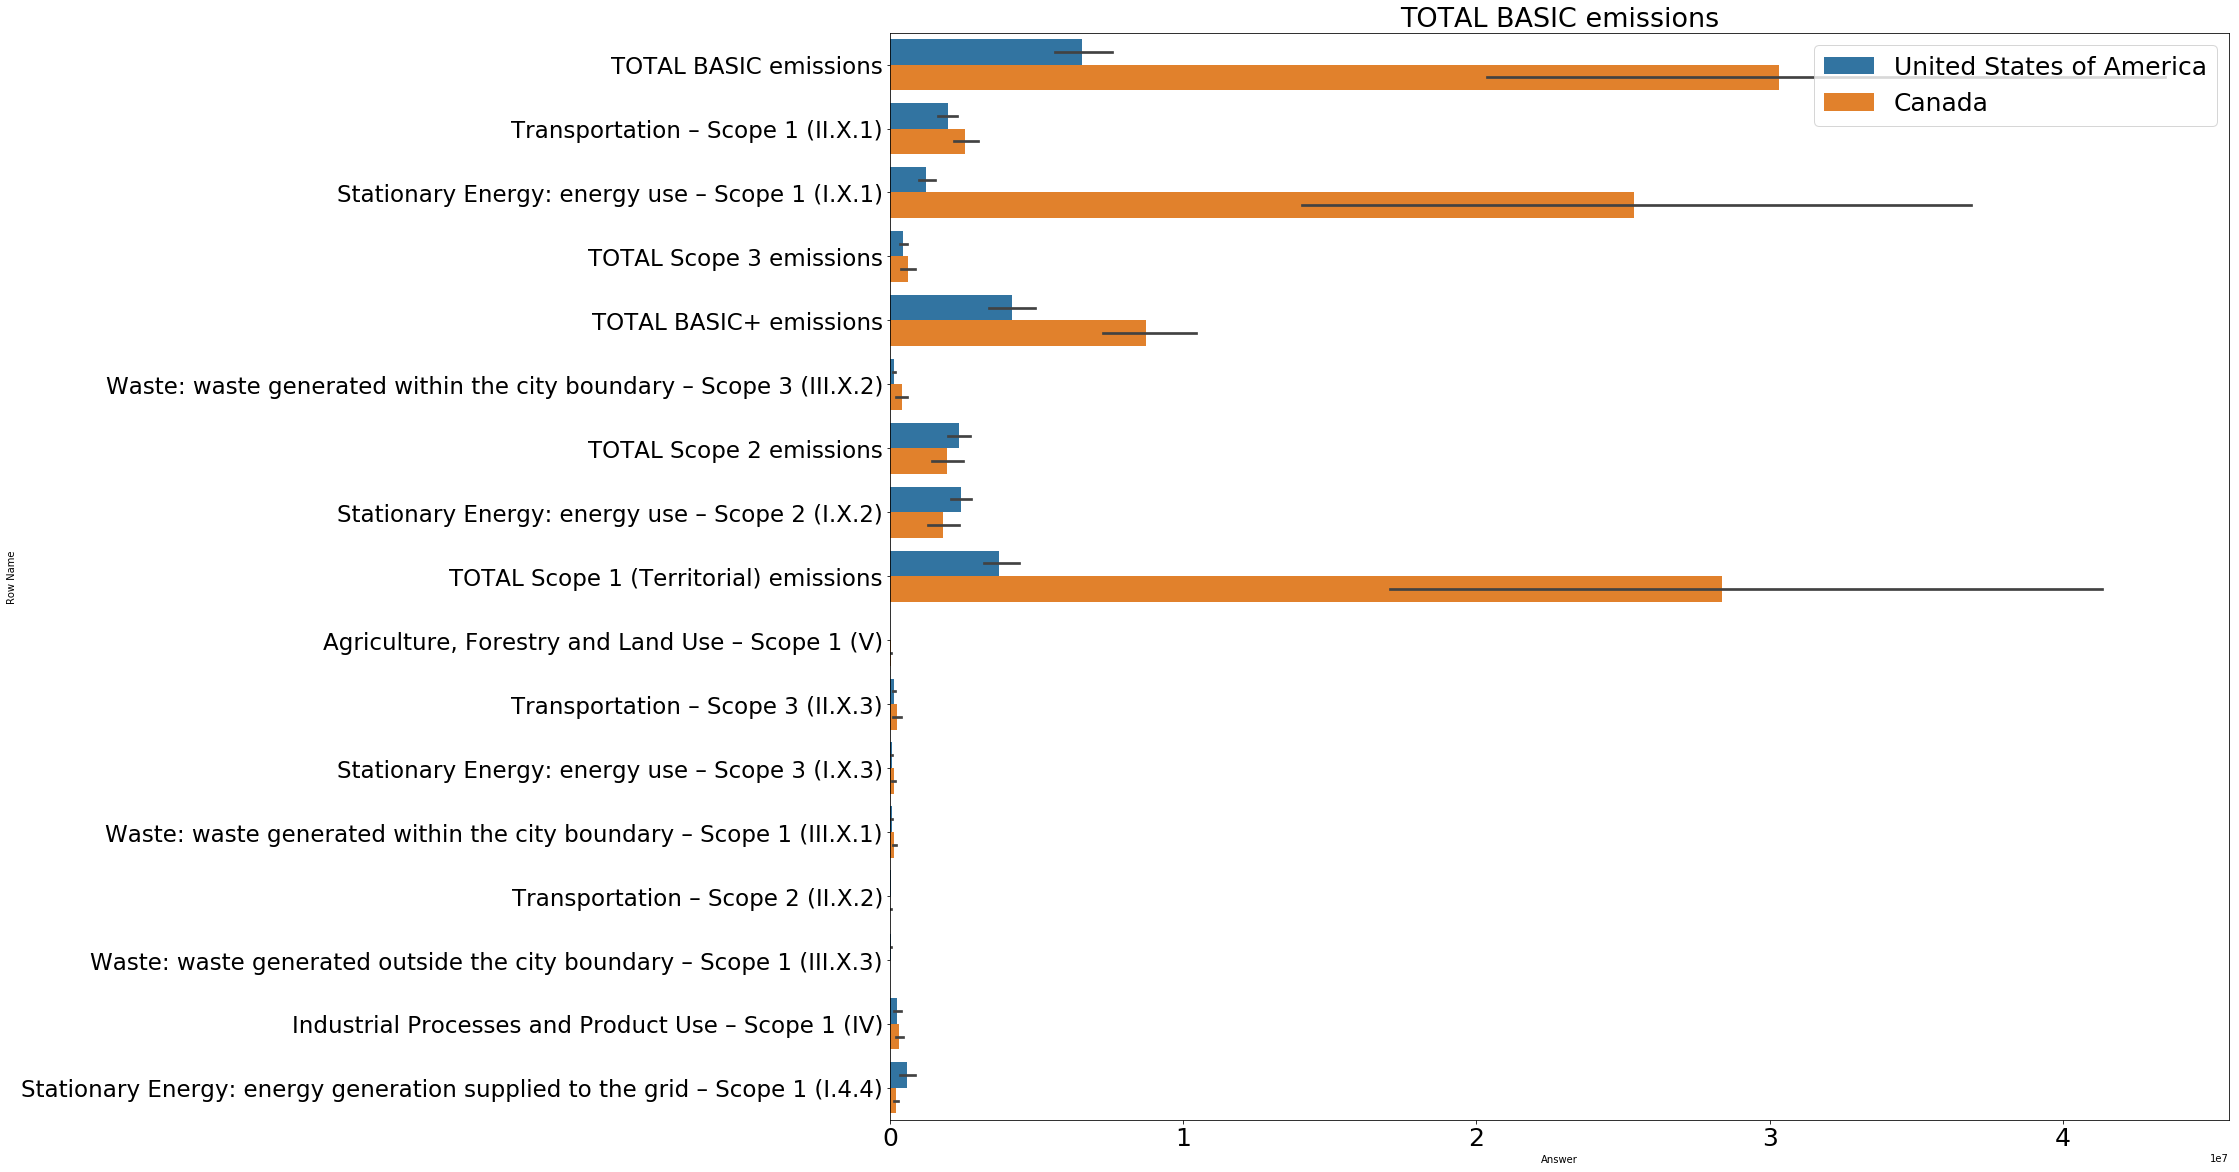

In [78]:
plt.rcParams['figure.figsize'] = (24, 20)
temp = ghgdf[ (ghgdf['Answer'] != 'No Response')
             & (ghgdf['Column Name'] == 'Emissions (metric tonnes CO2e)')
            ].copy()

temp['Answer'] = pd.to_numeric(temp['Answer'], downcast = "float")
ax = sns.barplot(y = 'Row Name', x = 'Answer', hue = 'Country', data = temp)
ax.set_title("TOTAL BASIC emissions", fontsize = 27)
plt.yticks(fontsize = 23); plt.xticks(fontsize = 25)
plt.legend(loc = 'upper right', fontsize = 25)
plt.show()

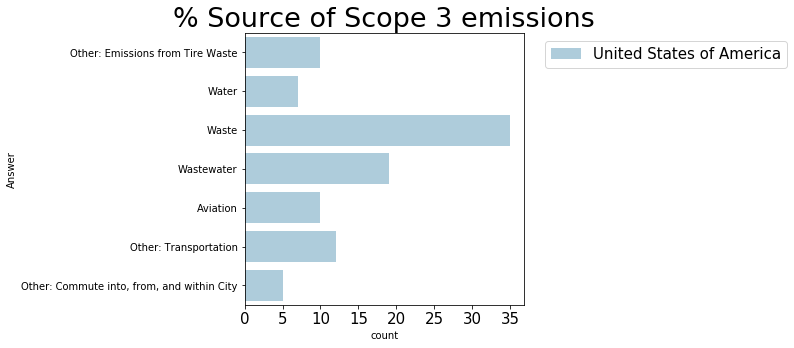

In [79]:
plt.rcParams['figure.figsize'] = (5, 5)
temp = ghgdf[ (ghgdf['Answer'] != 'No Response')
            & (ghgdf['Column Name'] == 'Source of Scope 3 emissions')].copy()

ax = sns.countplot(y = 'Answer', hue = 'Country', data = temp, palette=sns.color_palette("Paired"))
ax.set_title("% Source of Scope 3 emissions", fontsize = 27)
plt.xticks(fontsize = 15)
plt.legend(bbox_to_anchor = (1.05,1), fontsize = 15)
plt.show()

## CORPORATIONS 

In [89]:
# import thr corporate dataset
df_corp = pd.read_csv(r'datasets\Corporations\Corporations Disclosing\Climate Change\2018_Corporates_Disclosing_to_CDP_Climate_Change.csv')

In [90]:
df_corp.sample(3)

,account_number,organization,survey_year,country,region,invitation_status,public,samples,response_received_date,minimum_tier,...,authority_types,activities,sectors,industries,primary_activity,primary_sector,primary_industry,primary_questionnaire_sector,primary_ticker,tickers
135,333,"Adobe, Inc.",2018,United States of America,NaN,Submitted,public,"Benchmark, CCGR1000, CCGR1800, FTSE All-World...",2018-08-15T00:00:00Z,Climate Change - Full,...,"Investor, Supply Chain",Software,IT & software development,Services,Software,IT & software development,Services,General,ADBE US,ADBE US
308,17652,Starbucks Corporation,2018,United States of America,NaN,Submitted,public,"Agriculture, Benchmark, CCGR1000, CCGR1800, E...",2018-08-14T00:00:00Z,Climate Change - Full,...,"Investor, Supply Chain","Food & beverage amenities, Food & beverage wh...","Bars, hotels & restaurants, Trading, wholesal...","Hospitality, Retail",Food & beverage amenities,"Bars, hotels & restaurants",Hospitality,General,SBUX US,SBUX US
31,14961,Power Financial Corporation,2018,Canada,NaN,Submitted,public,"Benchmark, Canada, CCGR1800, FTSE All-World",2018-09-05T00:00:00Z,Climate Change - Full,...,Investor,"Asset managers, Insurance",Financial services,Services,Insurance,Financial services,Services,General,PWF CN,PWF CN


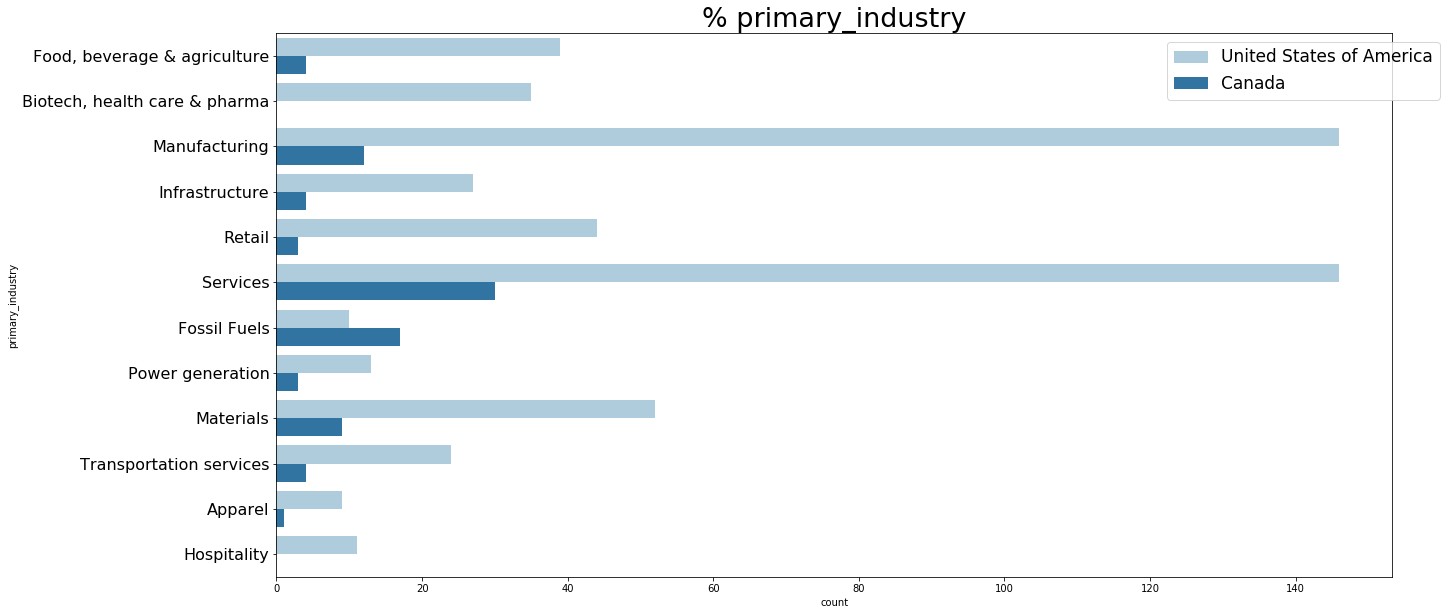

In [95]:
plt.rcParams['figure.figsize'] = (20, 10)
temp = df_corp.copy()

ax = sns.countplot(y = 'primary_industry', hue = 'country',  data = temp, palette=sns.color_palette("Paired"))
ax.set_title("% primary_industry", fontsize = 27)
plt.yticks( fontsize = 16)
plt.legend(bbox_to_anchor = (1.05,1), loc = 'upper right', fontsize = 17)
plt.show()

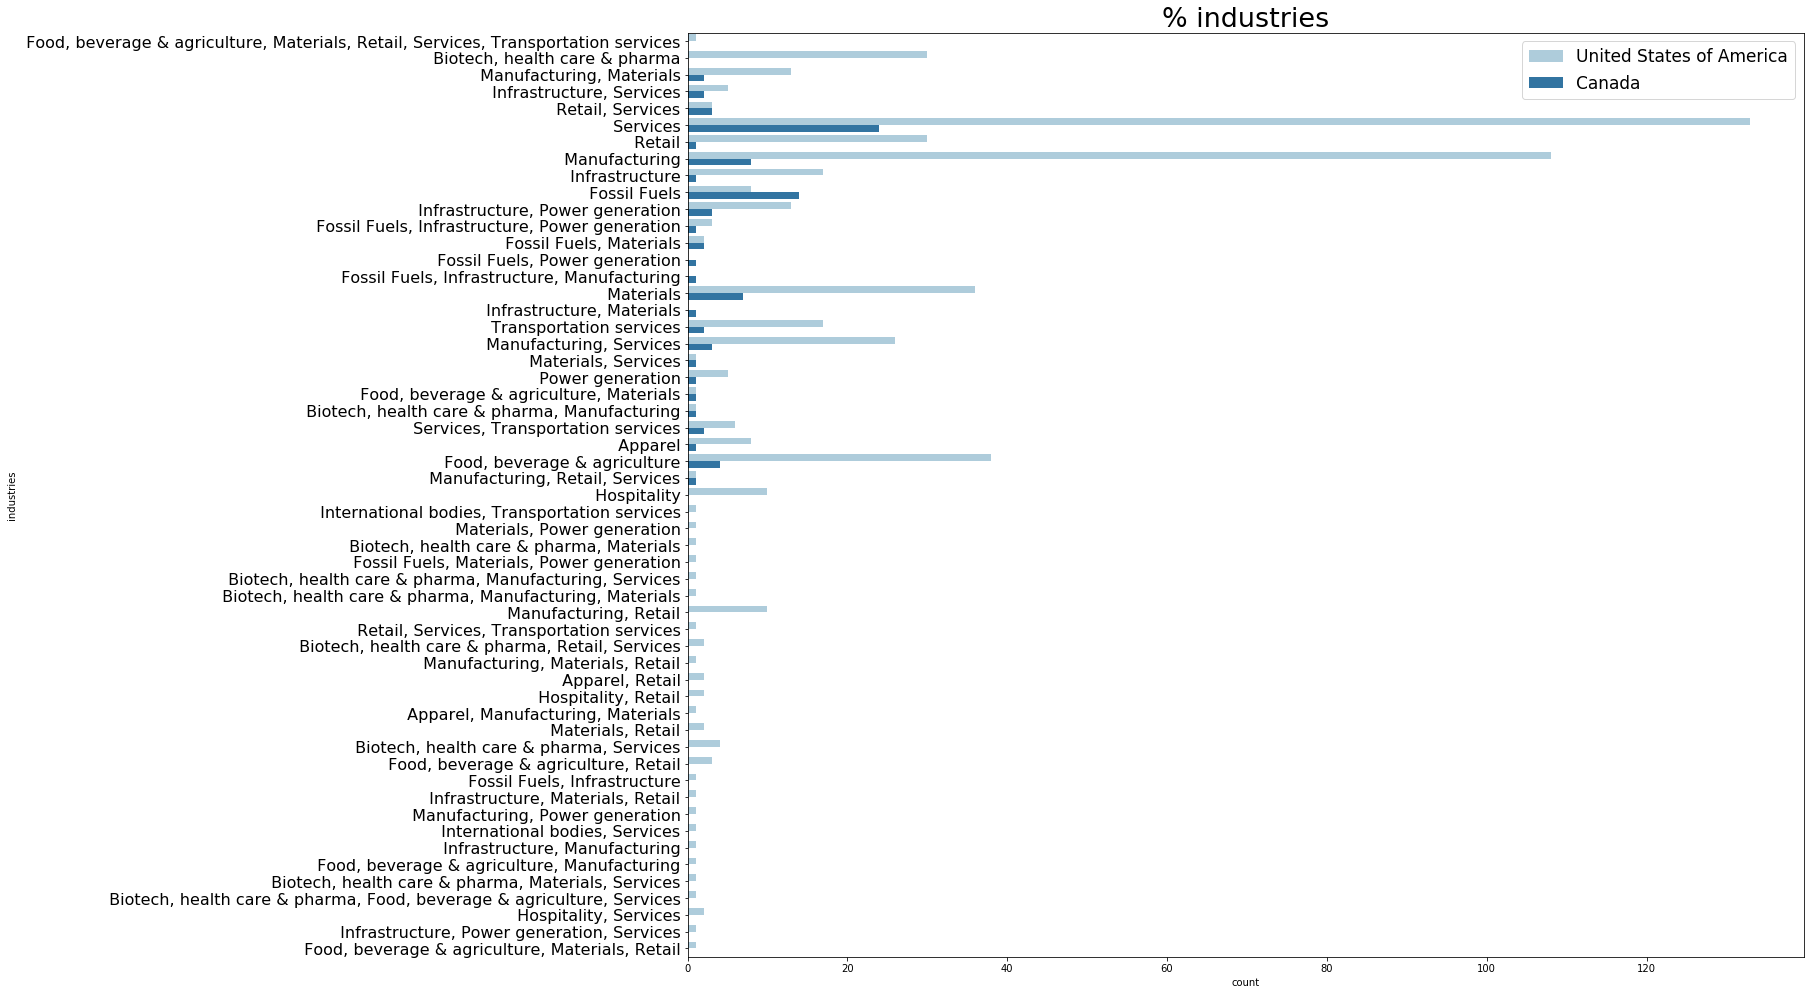

In [98]:
plt.rcParams['figure.figsize'] = (20, 17)
temp = df_corp.copy()

ax = sns.countplot(y = 'industries', hue = 'country',  data = temp, palette=sns.color_palette("Paired"))
ax.set_title("% industries", fontsize = 27)
plt.yticks( fontsize = 16)
plt.legend(loc = 'upper right', fontsize = 17)
plt.show()

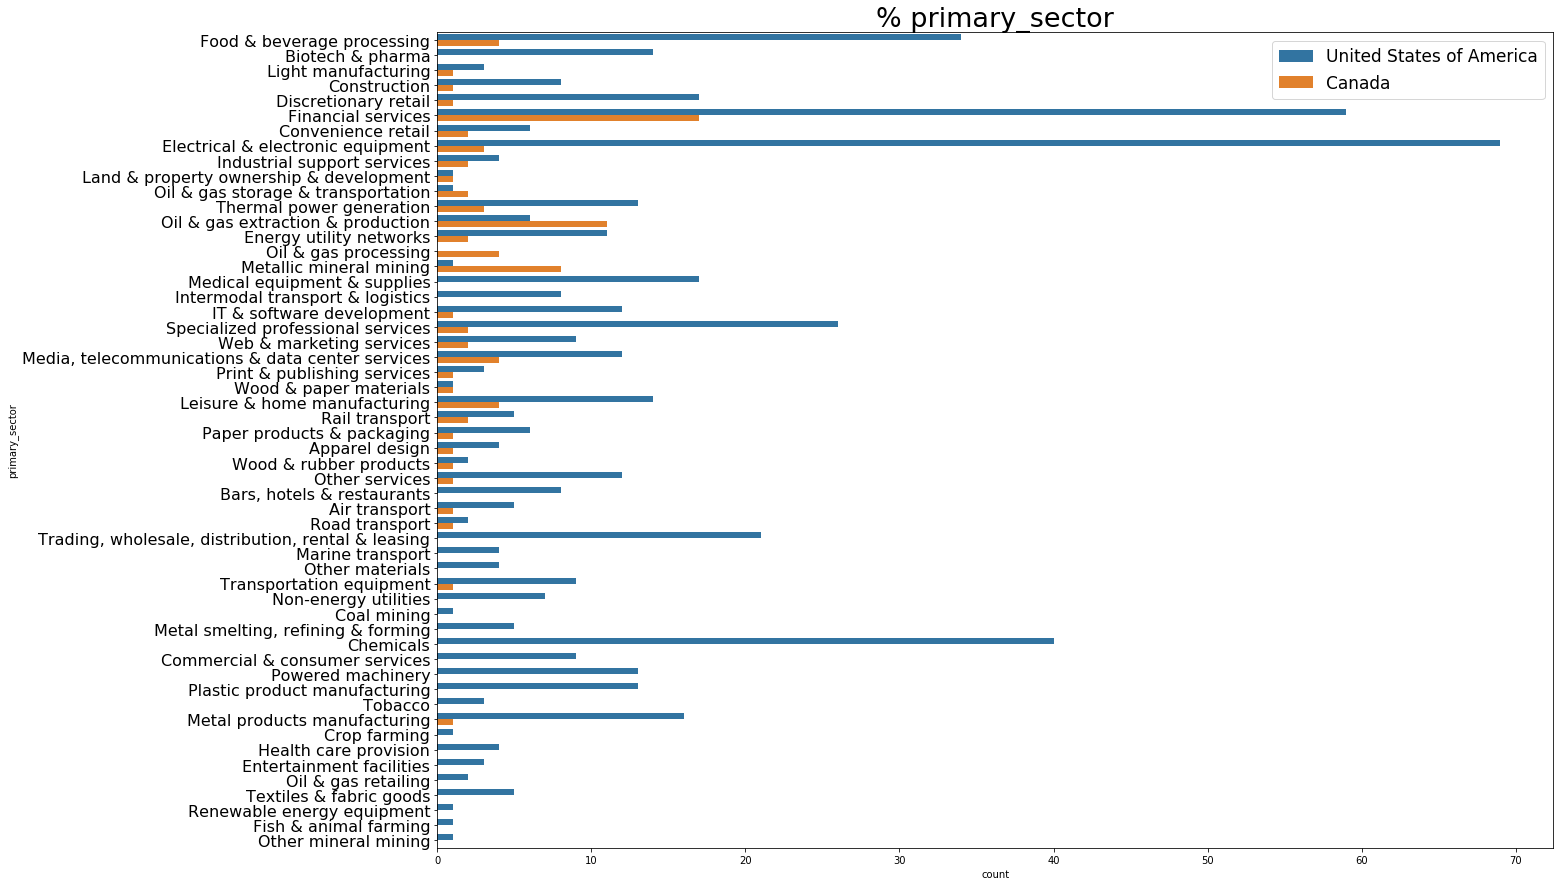

In [101]:
plt.rcParams['figure.figsize'] = (20, 15)
temp = df_corp.copy()

ax = sns.countplot(y = 'primary_sector', hue = 'country',  data = temp)
ax.set_title("% primary_sector", fontsize = 27)
plt.yticks( fontsize = 16)
plt.legend(loc = 'upper right', fontsize = 17)
plt.show()

Canada is more functional in Fossil Fuels, oil and gas processing, and metallic minerals mining

In [103]:
# import corporate response dataset

df_corp_resp = pd.read_csv(r'datasets\Corporations\Corporations Responses\Climate Change\2018_Full_Climate_Change_Dataset.csv')

In [104]:
df_corp_resp.sample(3)

,account_number,organization,survey_year,response_received_date,accounting_period_to,ors_response_id,submission_date,page_name,module_name,question_number,question_unique_reference,column_number,column_name,table_columns_unique_reference,row_number,row_name,data_point_name,data_point_id,response_value,comments
245479,18553,Teradyne Inc.,2018,2018-08-07T00:00:00Z,NaN,29745,2018-10-03T18:04:28Z,C7.3b,C7. Emissions breakdowns,C7.3b,Break down your total gross global Scope 1 emi...,1.0,C7.3b_C1Facility,C7.3b_c1-Facility,12,NaN,C7.3b_C1_Break down your total gross global Sc...,203,TER-NR-MA-US-500,NaN
199358,13117,Newmont Mining Corporation,2018,2018-08-10T00:00:00Z,NaN,24714,2018-10-02T16:56:46Z,C4.1b,C4. Targets and performance,C4.1b,Provide details of your emissions intensity ta...,8.0,C4.1b_C8Normalized baseline year emissions cov...,C4.1b_c8-Normalized baseline year emissions co...,1,NaN,C4.1b_C8_Provide details of your emissions int...,53,0.88,NaN
320720,1328,Ball Corporation,2018,2018-09-19T00:00:00Z,NaN,13927,2018-09-19T20:20:35Z,C6.5,C6. Emissions data,C6.5,Account for your organizationâ€™s Scope 3 emis...,3.0,C6.5_C3Emissions calculation methodology,C6.5_c3-Emissions calculation methodology,13,Downstream leased assets,C6.5_C3_Account for your organizationâ€™s Scop...,280,NaN,NaN


In [105]:
df_corp_resp['response_value'].fillna("No Response", inplace = True)

In [106]:
df_corp_resp['module_name'].value_counts()

C7. Emissions breakdowns       73101
C6. Emissions data             70362
C2. Risks and opportunities    69061
C4. Targets and performance    60271
C8. Energy                     42817
C12. Engagement                10979
C0. Introduction                4931
Name: module_name, dtype: int64

In [107]:
df_corp_resp[df_corp_resp['module_name'] == 'C7. Emissions breakdowns']['column_name'].value_counts()

C7.6b_C2Scope 2 location-based emissions (metric tons CO2e)                                                              4695
C7.6b_C3Scope 2, market-based emissions (metric tons CO2e)                                                               4695
C7.6b_C1Facility                                                                                                         4695
C7.5_C5Purchased and consumed low-carbon electricity, heat, steam or cooling accounted in market-based approach (MWh)    4687
C7.5_C4Purchased and consumed electricity, heat, steam or cooling (MWh)                                                  4687
C7.5_C3Scope 2, market-based (metric tons CO2e)                                                                          4687
C7.5_C1Country/Region                                                                                                    4687
C7.5_C2Scope 2, location-based (metric tons CO2e)                                                                     

In [110]:
a = set(list(df_corp['account_number']))
b = set(list(df_corp_resp['account_number']))
print(len(a.intersection(b)), '(common entries in data)  --> can merge data')

650 (common entries in data)  --> can merge data


In [111]:
t1 = df_corp_resp[(df_corp_resp['module_name'] == 'C7. Emissions breakdowns')].copy()

df = pd.merge(t1, df_corp[["country", 'primary_sector', 'primary_industry', 'primary_activity', 'account_number']], on='account_number', how='inner')
df.drop_duplicates(subset=None, keep="first", inplace=True)

df.drop(['survey_year', 'response_received_date', 'accounting_period_to', 'ors_response_id', 'submission_date',
            'page_name', 'module_name', 'row_number', 'comments',
           'table_columns_unique_reference', 'data_point_name', 'data_point_id'], axis = 1, inplace = True)

To determine the emission rates and amount from corporate dataset(emission information for each organisation), the response file is merged with corporate disclosing dataset(organization location wiht type of its industry and primary activities and sector information).

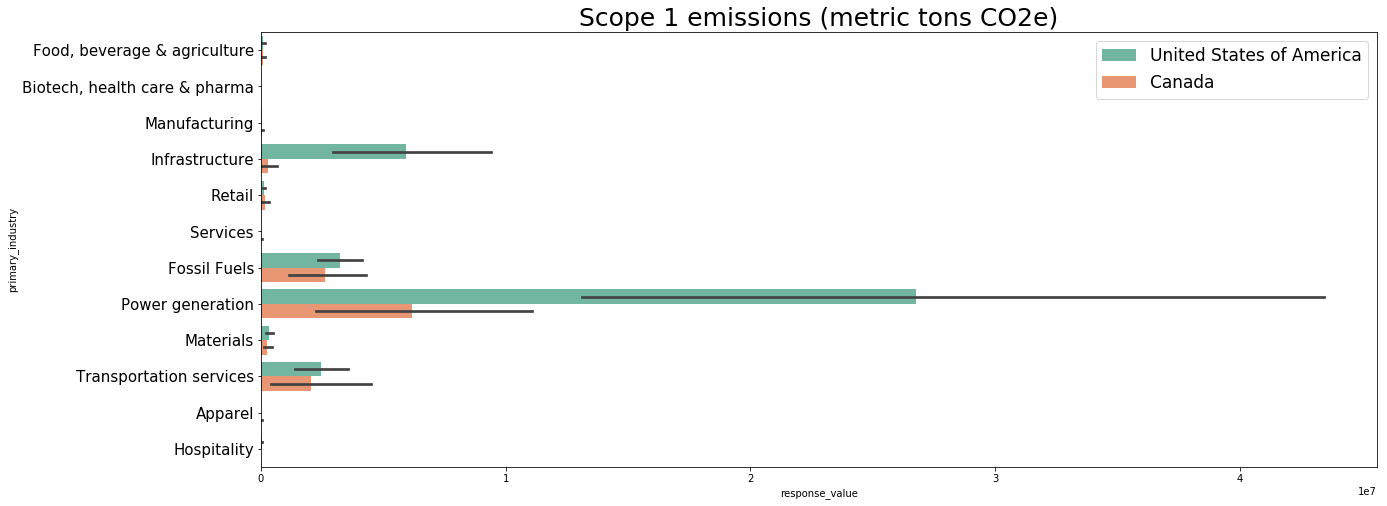

In [125]:
plt.rcParams['figure.figsize'] = (20, 8)
temp = df[(df['response_value'] != 'No Response')
            & (df['column_name'] == 'C7.2_C2Scope 1 emissions (metric tons CO2e)')].copy()

temp['response_value'] = pd.to_numeric(temp['response_value'], downcast = "float")
ax = sns.barplot(y = 'primary_industry', x = 'response_value', hue = 'country',  data = temp, palette=sns.color_palette("Set2"))
ax.set_title("Scope 1 emissions (metric tons CO2e)", fontsize = 25)
plt.yticks (fontsize = 15)
plt.legend(loc = 'upper right', fontsize = 17)
plt.show()

According to corporate data, Scope 1 emissions are mainly generated where the industries are mainly of the type => Power generarion and infrastructure along wiht Transportation .
This does matches to the city response data where scope 1 emission is found in large quantities for Buildins and municipal vehicle fleet releasing Fuel as oil gas and Diesel 

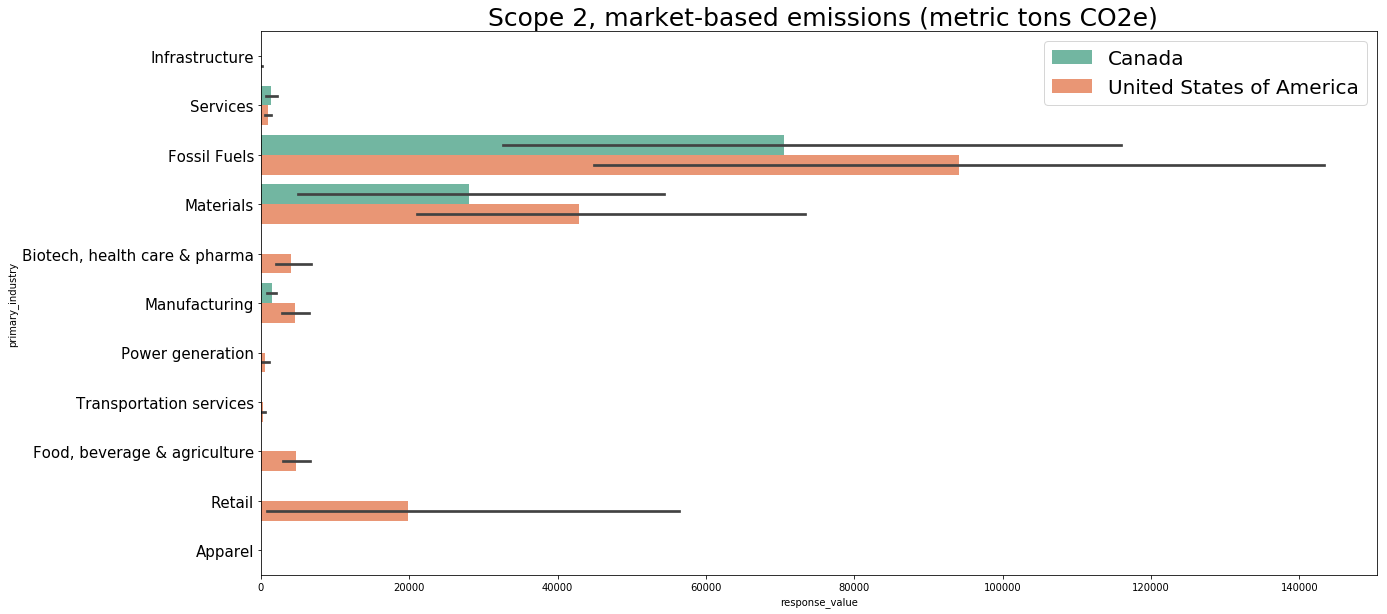

In [114]:
plt.rcParams['figure.figsize'] = (20, 10)
temp = df[(df['response_value'] != 'No Response')
            & (df['column_name'] == 'C7.6b_C3Scope 2, market-based emissions (metric tons CO2e)')].copy()

temp['response_value'] = pd.to_numeric(temp['response_value'], downcast = "float")
ax = sns.barplot(y = 'primary_industry', x = 'response_value', hue = 'country',  data = temp, palette=sns.color_palette("Set2"))
ax.set_title(" Scope 2, market-based emissions (metric tons CO2e)", fontsize = 25)
plt.yticks(fontsize = 15)
plt.legend(loc = 'upper right', fontsize = 20)
plt.show()

Scope 2 emission is mainly found in regions where there are industries mainly responsible for Fossil Fuels, Materials and reatil services as their primary activities.

##### The location-based method reveals what the company is physically putting into the air, and the market-based method shows emissions the company is responsible for through its purchasing decisions.

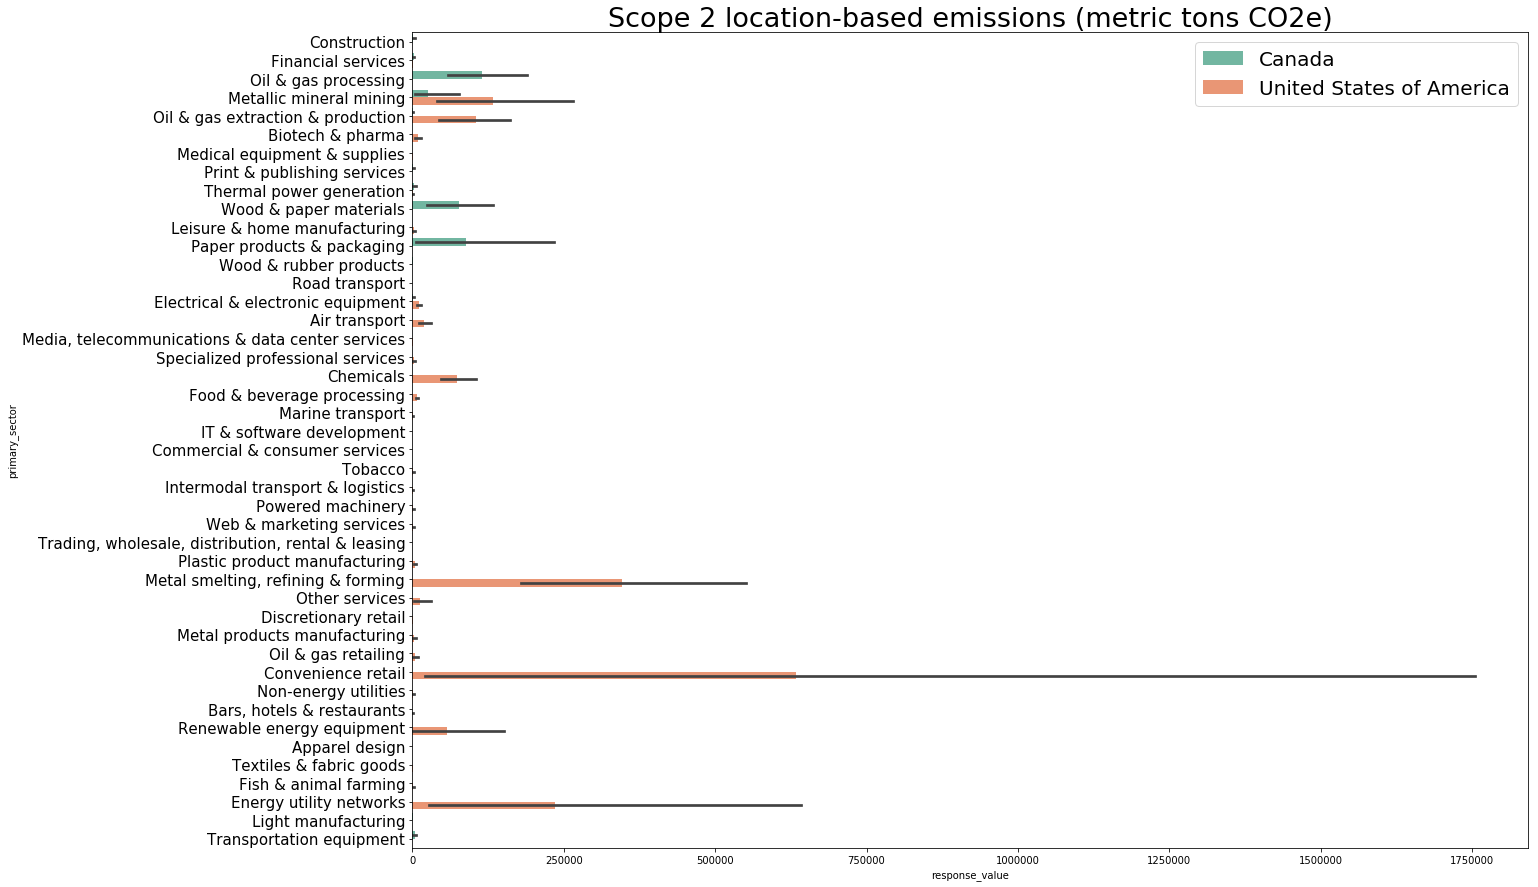

In [118]:
plt.rcParams['figure.figsize'] = (20, 15)
temp = df[(df['response_value'] != 'No Response')
            & (df['column_name'] == 'C7.6b_C2Scope 2 location-based emissions (metric tons CO2e)')].copy()

temp['response_value'] = pd.to_numeric(temp['response_value'], downcast = "float")
ax = sns.barplot(y = 'primary_sector', x = 'response_value', hue = 'country',  data = temp, palette=sns.color_palette("Set2"))
ax.set_title("Scope 2 location-based emissions (metric tons CO2e)", fontsize = 27)
plt.yticks(fontsize = 15)
plt.legend(loc = 'upper right', fontsize = 20)
plt.show()

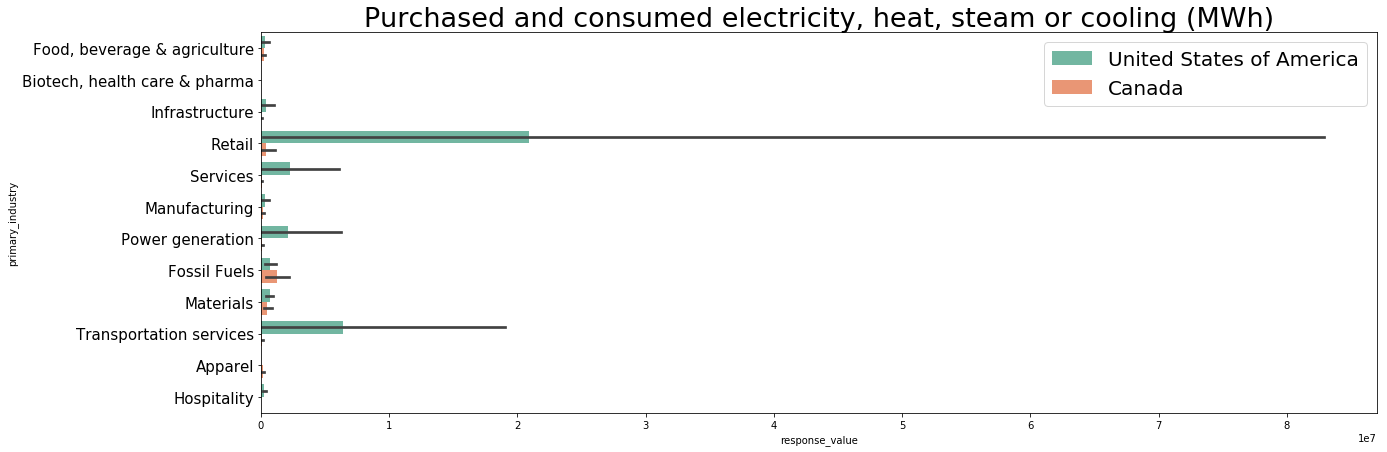

In [121]:
plt.rcParams['figure.figsize'] = (20, 7)
temp = df[(df['response_value'] != 'No Response')
            & (df['column_name'] == 'C7.5_C4Purchased and consumed electricity, heat, steam or cooling (MWh)')].copy()

temp['response_value'] = pd.to_numeric(temp['response_value'], downcast = "float")
ax = sns.barplot(y = 'primary_industry', x = 'response_value', hue = 'country',  data = temp, palette=sns.color_palette("Set2"))
ax.set_title("Purchased and consumed electricity, heat, steam or cooling (MWh)", fontsize = 27)
plt.yticks(fontsize = 15)
plt.legend(loc = 'upper right', fontsize = 20)
plt.show()

Retail and Transportation industries require more amount of electricity.

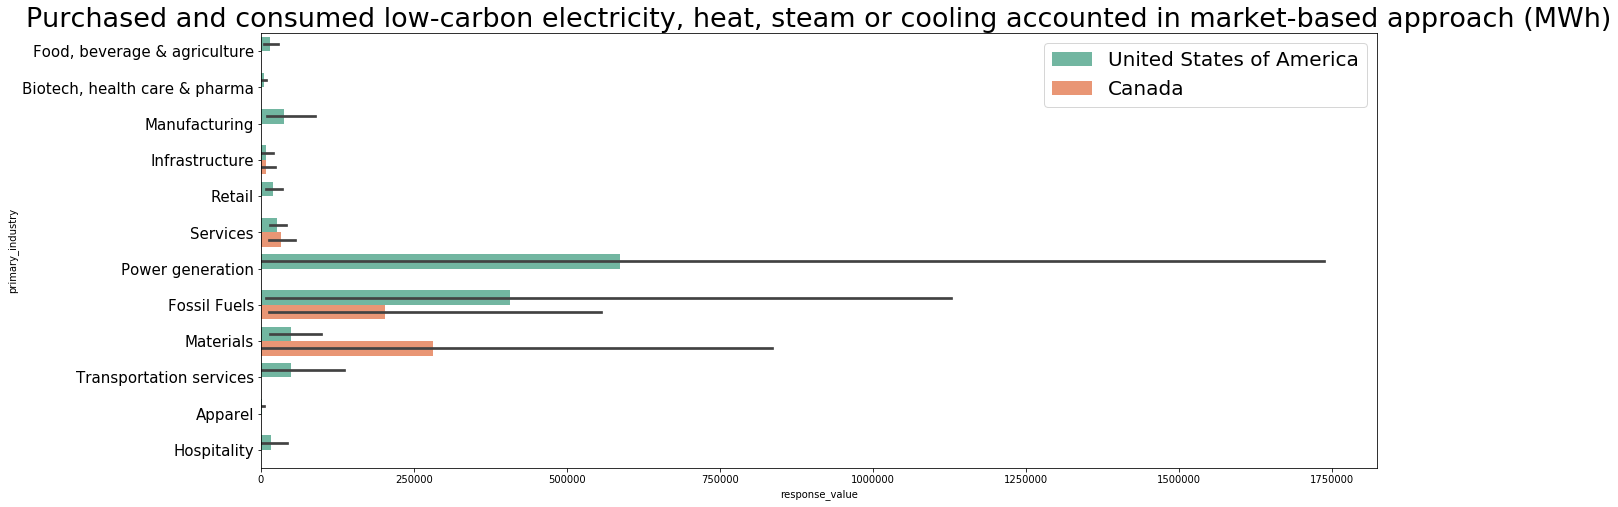

In [122]:
plt.rcParams['figure.figsize'] = (20, 8)
temp = df[(df['response_value'] != 'No Response')
            & (df['column_name'] == 'C7.5_C5Purchased and consumed low-carbon electricity, heat, steam or cooling accounted in market-based approach (MWh)')].copy()

temp['response_value'] = pd.to_numeric(temp['response_value'], downcast = "float")
ax = sns.barplot(y = 'primary_industry', x = 'response_value', hue = 'country',  data = temp, palette=sns.color_palette("Set2"))
ax.set_title("Purchased and consumed low-carbon electricity, heat, steam or cooling accounted in market-based approach (MWh)", fontsize = 27)
plt.yticks(fontsize = 15)
plt.legend(loc = 'upper right', fontsize = 20)
plt.show()

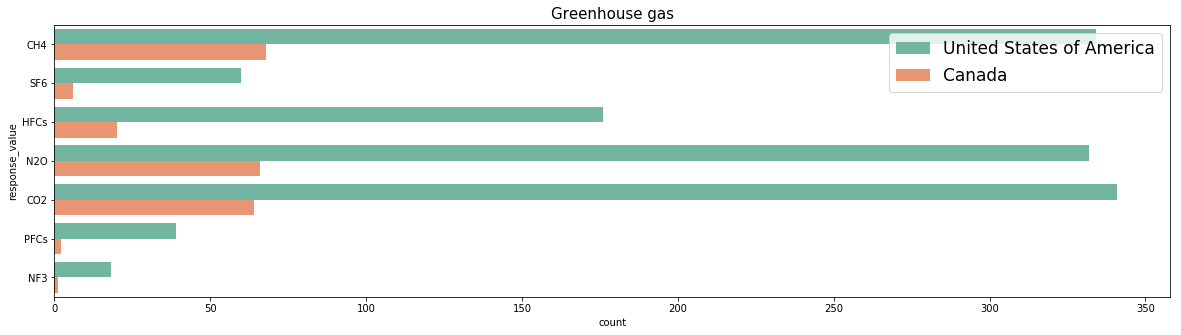

In [127]:
plt.rcParams['figure.figsize'] = (20, 5)
temp = df[(df['response_value'] != 'No Response')
            & (df['column_name'] == 'C7.1a_C1Greenhouse gas')].copy()

temp = df[(df['response_value'] == 'CO2') | (df['response_value'] == 'CH4')
            | (df['response_value'] == 'N2O') | (df['response_value'] == 'HFCs')
         | (df['response_value'] == 'SF6') | (df['response_value'] == 'PFCs')
          | (df['response_value'] == 'NF3')].copy()

ax = sns.countplot(y = 'response_value', hue = 'country',  data = temp, palette=sns.color_palette("Set2"))
ax.set_title("Greenhouse gas", fontsize = 15)
plt.legend(loc = 'upper right', fontsize = 17)
plt.show()